# 第04章 矩阵的解剖 · B1组（G3）独立验证与复现

| 被审组 | 稿件 | 本组核对范围 |
| --- | --- | --- |
| A1（G14） | `A1-G14-正文.md`、`A1组-实验.ipynb` | 4.1–4.4 四节全部结论与实验：正文数字 ↔ Notebook 输出 ↔ 本组独立实现，三方对照 |
| A2（G18） | `A2-G18-正文.md`、`A2组-实验.ipynb` | 同上 |

- **本组**：B1组＝G3（第04章第 1 个 B 组）；日期 2026-11-10。
- **复现口径**：**先写预测与参考值，再运行**。参考值只来自解析式、手算、`numpy.linalg` / `scipy.linalg` 的独立函数或预先指定的制造真解；不把被审程序自己的输出当作真值。
- **记录方式**：每个代码单元用 `check()` 记一次通过/不通过，并保存真实输出；不通过的地方不隐藏，直接列在"未通过"清单里。
- **分工**：本 Notebook 只回答"能不能复现、数值对不对、结论是否被数据支持"；逐条修改意见见 `B1-G3-修正清单.md`，比对结论见 `B1-G3-验证报告.md`，AI 使用与人工纠错留痕见 `B1-G3-AI对话记录.md`。
- **读法**：每组先看"先给 X 点个赞"，再看各小节的"被审主张 → 本组实测"，末尾的 check 是判定；I.8、II.9 是两组的复现小结，第三部分是两份稿子的交叉核对。
- **独立环境**：本组另建环境（Python 3.14 / NumPy 2.5 / SciPy 1.18，未装 PyTorch），与 A 组记录的 Python 3.12 / NumPy 1.26 / SciPy 1.14 **不同**，可以顺带检查结论是否依赖单一库版本。

**目录**

- 第一部分 A1（G14）：I.1 4.1 直接法｜I.2 小主元与输入舍入｜I.3 病态候选解｜I.4 4.2 CG/预条件｜I.5 三对角测例是否退化｜I.6 4.3 六个实验｜I.7 4.4 三路梯度与 PCA/LoRA｜I.8 G14 小结
- 第二部分 A2（G18）：II.1 4.1 LU/Cholesky｜II.2 三位有效数字例｜II.3 乘数有界≠误差可控｜II.4 4.2 缩放三对角系统｜II.5 控制实验与超过 n 步｜II.6 4.3 SVD｜II.7 4.4 三路梯度与 PCA/LoRA｜II.8 4.4.4 三个论断的反例｜II.9 G18 小结
- 第三部分 交叉核对：两组结论对照、报告数字与保存输出是否一致、复现条件与局限

In [1]:
# B1 公共单元：环境记录 + 本组独立实现（B 组自写，不复制 A 组代码）
import sys, platform, time, itertools
from datetime import datetime
import numpy as np
import scipy
from scipy import linalg as sla
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR)   # 屏蔽本机数学字体缺字形的日志噪声
from IPython.display import display, Markdown, Image

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=8, suppress=True)

def log_fmt(y, _):
    '''把对数刻度写成 1eN 的 ASCII 形式，避免数学字体缺字形。'''
    if y <= 0:
        return ''
    return '1e%d' % int(round(np.log10(y)))

def logaxis(ax):
    ax.yaxis.set_major_formatter(FuncFormatter(log_fmt))
    ax.yaxis.set_minor_formatter(FuncFormatter(lambda y, _: ''))

EPS = np.finfo(float).eps
CHECKS = []

def check(name, cond, detail=''):
    ok = bool(cond)
    CHECKS.append({'name': name, 'ok': ok, 'detail': str(detail)})
    print(('  [通过] ' if ok else '  [未通过] ') + name + ('' if not detail else ' | ' + str(detail)))

def relerr(a, b):
    a = np.asarray(a, dtype=float).ravel(); b = np.asarray(b, dtype=float).ravel()
    den = np.linalg.norm(b)
    return float(np.linalg.norm(a - b) / den) if den else float(np.linalg.norm(a - b))

def show(title, headers, rows):
    txt = '**' + title + '**\n\n| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    for r in rows:
        cells_ = ['%.6g' % x if isinstance(x, float) else str(x) for x in r]
        txt += '| ' + ' | '.join(cells_) + ' |\n'
    display(Markdown(txt))

def summary():
    bad = [c for c in CHECKS if not c['ok']]
    print('累计检查 %d 项：通过 %d，未通过 %d' % (len(CHECKS), len(CHECKS) - len(bad), len(bad)))
    for c in bad:
        print('   ✗', c['name'], '|', c['detail'])

# ---------- 4.1 直接法：本组独立实现 ----------
def lu_pp(A):
    '''列主元 LU：返回 p, L, U，满足 A[p, :] = L @ U。'''
    U = np.array(A, dtype=float); n = len(U)
    L = np.eye(n); p = np.arange(n)
    for k in range(n):
        q = k + int(np.argmax(np.abs(U[k:, k])))
        if U[q, k] == 0.0:
            raise np.linalg.LinAlgError('zero pivot')
        if q != k:
            U[[k, q], :] = U[[q, k], :]
            p[[k, q]] = p[[q, k]]
            L[[k, q], :k] = L[[q, k], :k]     # 只换已存乘子
        for i in range(k + 1, n):
            L[i, k] = U[i, k] / U[k, k]
            U[i, k + 1:] -= L[i, k] * U[k, k + 1:]
            U[i, k] = 0.0
    return p, L, U

def fsub(L, B):
    B = np.asarray(B, dtype=float)
    if B.ndim == 1:
        B = B[:, None]
    Y = np.zeros_like(B)
    for i in range(L.shape[0]):
        Y[i] = (B[i] - L[i, :i] @ Y[:i]) / L[i, i]
    return Y

def bsub(U, Y):
    X = np.zeros_like(Y)
    for i in range(U.shape[0] - 1, -1, -1):
        X[i] = (Y[i] - U[i, i + 1:] @ X[i + 1:]) / U[i, i]
    return X

def solve_lu(p, L, U, B):
    '''多右端与单右端通用；返回 (n, s) 或 (n,)。'''
    B = np.asarray(B, dtype=float)
    one = (B.ndim == 1)
    if one:
        B = B[:, None]
    X = bsub(U, fsub(L, B[p, :]))
    return X.ravel() if one else X

def chol_lower(A):
    A = np.array(A, dtype=float); n = len(A)
    if not np.allclose(A, A.T, rtol=0, atol=1e-14):
        raise ValueError('not symmetric')
    L = np.zeros_like(A)
    for j in range(n):
        d = A[j, j] - L[j, :j] @ L[j, :j]
        if d <= 0:
            raise np.linalg.LinAlgError('not positive definite')
        L[j, j] = np.sqrt(d)
        for i in range(j + 1, n):
            L[i, j] = (A[i, j] - L[i, :j] @ L[j, :j]) / L[j, j]
    return L

def solve_chol(L, B):
    return bsub(L.T, fsub(L, B))

# ---------- 4.2 迭代法：一个函数，两种停止判据 ----------
def cg(A, b, tol=1e-8, maxiter=None, mdiag=None, true_residual=False):
    '''CG / 对角预条件 CG。
    mdiag=None 即标准 CG；true_residual=True 时每步重算真实残差再判停（A2 的写法），
    否则用递归残差判停（A1 的写法）。返回 (x, 迭代次数, 残差历史)。'''
    n = len(b); x = np.zeros(n)
    maxiter = 5 * n if maxiter is None else maxiter
    md = np.ones(n) if mdiag is None else np.asarray(mdiag, dtype=float)
    r = b - A @ x
    bn = np.linalg.norm(b)
    hist = [float(np.linalg.norm(r) / bn)]
    z = r / md; p = z.copy(); rz = float(r @ z)
    for k in range(maxiter):
        Ap = A @ p
        alpha = rz / float(p @ Ap)
        x = x + alpha * p
        r = r - alpha * Ap
        hist.append(float(np.linalg.norm(b - A @ x) / bn) if true_residual else float(np.linalg.norm(r) / bn))
        if hist[-1] <= tol:
            return x, k + 1, np.array(hist)
        z = r / md
        rzn = float(r @ z)
        p = z + (rzn / rz) * p
        rz = rzn
    return x, maxiter, np.array(hist)

def cg_recursive(A, b, tol=1e-8, **kw):
    return cg(A, b, tol=tol, true_residual=False, **kw)

def cg_true(A, b, tol=1e-8, **kw):
    return cg(A, b, tol=tol, true_residual=True, **kw)

def median_time(fn, reps=7):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

print('Python %s | NumPy %s | SciPy %s | %s' % (platform.python_version(), np.__version__, scipy.__version__, platform.machine()))
print('设备 CPU | dtype float64 | 运行时刻 %s' % datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('float64 机器精度 eps = %.17e' % EPS)
try:
    import torch
    print('PyTorch:', torch.__version__)
except ImportError:
    print('PyTorch: 未安装（与 A 组相同的环境限制；本组另用复数步长微分补第三路，见 I.7 / II.7）')

Python 3.14.6 | NumPy 2.5.3 | SciPy 1.18.1 | AMD64
设备 CPU | dtype float64 | 运行时刻 2026-11-10 11:07:51
float64 机器精度 eps = 2.22044604925031308e-16
PyTorch: 未安装（与 A 组相同的环境限制；本组另用复数步长微分补第三路，见 I.7 / II.7）


## 第一部分　A1（G14）的独立复现

被审文件：`A1-G14-正文.md`（2103 行）+ `A1组-实验.ipynb`（40 个单元，已保存输出）。

核查按正文小节顺序进行。每个小节先列出**被审稿的主张和它给出的数字**，再给**本组参考值/预期**，最后给**实测**，并判断"能否复现"。

### 先给 G14 点个赞

在列问题之前，先说几件这份稿子做得**确实漂亮**的事——这些也是本组复现时最省力的地方：

1. **4.1 的推导是"能自己走通"的那种。** 从消元矩阵 $E_k=I-v_ke_k^T$ 推出 $L=I+\sum_k v_ke_k^T$，再单独用分块证明"换行时只交换 $L$ 已完成的列"。本组按这个思路独立实现，一步没错。
2. **故障注入和预期失败。** 故意漏换 $L$ 乘子，再看 $PA-LU$ 的误差变成 0.5——这是很专业的自检手法；对非正定、非对称、奇异输入要求必须抛异常，也没有偷懒。
3. **用 `Fraction` 区分"输入舍入"与"算法误差"。** 这个细节本组直接沿用，并在 I.2 里接着往前推了一步。
4. **4.3 的八个推导是真证明。** 谱定理、SVD 存在性、Weyl、Eckart–Young、幂迭代都写全了，而且每条末尾都有"条件不满足时会怎样"。
5. **4.4 的分寸感。** 明确写了"PyTorch 未安装、自动微分未验证"，也反复强调"LoRA 不是对 $W_0$ 做截断 SVD"——不硬凑结论，这一点很难得。

所以下面的问题都是"局部要不要改"，不是"整体不行"。

### I.1　4.1 直接法：PA=LU、Cholesky 与多右端

**被审主张**（正文 4.1 节，实验单元 3–5）

1. 例题 $A=\begin{bmatrix}0&2&1\\1&1&0\\2&0&1\end{bmatrix}$ 需两次换行，最终 $p=(2,0,1)$、$L=\begin{bmatrix}1&0&0\\0&1&0\\1/2&1/2&1\end{bmatrix}$、$U=\begin{bmatrix}2&0&1\\0&2&1\\0&0&-1\end{bmatrix}$，解 $x=(1,2,-1)^T$。
2. 正定矩阵 $H=\begin{bmatrix}4&2&2\\2&5&1\\2&1&3\end{bmatrix}$ 的 Cholesky 因子 $L_H=\begin{bmatrix}2&0&0\\1&2&0\\1&0&\sqrt2\end{bmatrix}$。
3. 分解一次、复用因子解两个右端，可恢复 $X_*=\begin{bmatrix}1&2\\2&0\\-1&1\end{bmatrix}$。
4. 验收阈值 $\tau=500n\,\mathrm{eps}\approx3.331\times10^{-13}$；正文表格中 LU 分解误差为 0，Cholesky 为 $5.551\times10^{-17}$。

**本组参考**：$X_*$ 与手算 $L,U$ 是预先给定的，不来自程序输出；另用 `np.linalg.solve` 与 `np.linalg.cholesky` 交叉对照。

In [3]:
# I.1 复现 4.1 主实验
A41g = np.array([[0., 2., 1.], [1., 1., 0.], [2., 0., 1.]])
b41g = np.array([3., 3., 1.])
Xs41 = np.array([[1., 2.], [2., 0.], [-1., 1.]])
B41 = A41g @ Xs41
tau3 = 500 * 3 * EPS

p, Lg, Ug = lu_pp(A41g)
xg = solve_lu(p, Lg, Ug, b41g)
Xg = solve_lu(p, Lg, Ug, B41)

H41 = np.array([[4., 2., 2.], [2., 5., 1.], [2., 1., 3.]])
Lh = chol_lower(H41)
Xh = solve_chol(Lh, H41 @ Xs41)

L_manual = np.array([[1., 0., 0.], [0., 1., 0.], [.5, .5, 1.]])
U_manual = np.array([[2., 0., 1.], [0., 2., 1.], [0., 0., -1.]])
Lh_manual = np.array([[2., 0., 0.], [1., 2., 0.], [1., 0., np.sqrt(2.)]])

rows = [
    ['LU 置换 p', '(2,0,1)', '同上', str(tuple(int(v) for v in p)), '一致' if tuple(p) == (2, 0, 1) else '不一致'],
    ['L 与手算值之差', 'L=[[1,0,0],[0,1,0],[.5,.5,1]]', '0', '%.3e' % relerr(Lg, L_manual), '一致' if relerr(Lg, L_manual) < 1e-15 else '不一致'],
    ['U 与手算值之差', 'U=[[2,0,1],[0,2,1],[0,0,-1]]', '0', '%.3e' % relerr(Ug, U_manual), '一致' if relerr(Ug, U_manual) < 1e-15 else '不一致'],
    ['(PA-LU)/|A|', '0（正文表）', '< tau', '%.3e' % relerr(Lg @ Ug, A41g[p, :]), '可复现'],
    ['单右端解 x 的相对误差', '(1,2,-1)', '< tau', '%.3e' % relerr(xg, [1., 2., -1.]), '一致' if relerr(xg, [1., 2., -1.]) < tau3 else '不一致'],
    ['多右端 X 的相对误差', 'X_*', '< tau', '%.3e' % relerr(Xg, Xs41), '一致' if relerr(Xg, Xs41) < tau3 else '不一致'],
    ['Cholesky 因子之差', '[[2,0,0],[1,2,0],[1,0,sqrt2]]', '0', '%.3e' % relerr(Lh, Lh_manual), '一致' if relerr(Lh, Lh_manual) < 1e-15 else '不一致'],
    ['(H-LL^T)/|H|', '5.551e-17（正文表）', '< tau', '%.3e' % relerr(Lh @ Lh.T, H41), '同量级'],
    ['Cholesky 多右端的相对误差', 'X_*', '< tau', '%.3e' % relerr(Xh, Xs41), '一致' if relerr(Xh, Xs41) < tau3 else '不一致'],
]
show('表 I-1　4.1 主实验：正文值 vs 本组复现', ['检查项', '正文/手算值', '本组预期', '本组实测', '结论'], rows)
print('tau = 500·n·eps = %.6e' % tau3)
print('库函数对照：||x - solve(A,b)||/||x|| = %.3e；|| |L_H| - |cholesky(H)| ||_F/||L_H||_F = %.3e'
      % (relerr(xg, np.linalg.solve(A41g, b41g)), relerr(np.abs(Lh), np.abs(np.linalg.cholesky(H41)))))

check('G14-4.1 置换与手算 L,U 一致', tuple(p) == (2, 0, 1) and relerr(Lg, L_manual) < 1e-15 and relerr(Ug, U_manual) < 1e-15)
check('G14-4.1 PA=LU 与多右端在 tau 内', relerr(Lg @ Ug, A41g[p, :]) < tau3 and relerr(Xg, Xs41) < tau3)
check('G14-4.1 Cholesky 因子与多右端在 tau 内', relerr(Lh, Lh_manual) < 1e-15 and relerr(Xh, Xs41) < tau3)
summary()

**表 I-1　4.1 主实验：正文值 vs 本组复现**

| 检查项 | 正文/手算值 | 本组预期 | 本组实测 | 结论 |
| --- | --- | --- | --- | --- |
| LU 置换 p | (2,0,1) | 同上 | (2, 0, 1) | 一致 |
| L 与手算值之差 | L=[[1,0,0],[0,1,0],[.5,.5,1]] | 0 | 0.000e+00 | 一致 |
| U 与手算值之差 | U=[[2,0,1],[0,2,1],[0,0,-1]] | 0 | 0.000e+00 | 一致 |
| (PA-LU)/|A| | 0（正文表） | < tau | 0.000e+00 | 可复现 |
| 单右端解 x 的相对误差 | (1,2,-1) | < tau | 0.000e+00 | 一致 |
| 多右端 X 的相对误差 | X_* | < tau | 0.000e+00 | 一致 |
| Cholesky 因子之差 | [[2,0,0],[1,2,0],[1,0,sqrt2]] | 0 | 0.000e+00 | 一致 |
| (H-LL^T)/|H| | 5.551e-17（正文表） | < tau | 5.385e-17 | 同量级 |
| Cholesky 多右端的相对误差 | X_* | < tau | 4.734e-17 | 一致 |


tau = 500·n·eps = 3.330669e-13
库函数对照：||x - solve(A,b)||/||x|| = 0.000e+00；|| |L_H| - |cholesky(H)| ||_F/||L_H||_F = 0.000e+00
  [通过] G14-4.1 置换与手算 L,U 一致
  [通过] G14-4.1 PA=LU 与多右端在 tau 内
  [通过] G14-4.1 Cholesky 因子与多右端在 tau 内
累计检查 6 项：通过 6，未通过 0


**复现结论（I.1）**：4.1 的主实验可以完整复现，本组实现与正文手算值、与库函数三路一致。这一节没有发现需要修改的结论。

需要提醒的是"零误差"的含义：本题的 $A$、$X_*$、$B$ 全是小整数，二进制可精确表示，消元过程也没有相减相消，因此相关误差**恰好为 0**。正文已经写明"不能据此断言 LU 一般没有舍入误差"，这一点处理得对。本组用同一份实现再跑一个随机三阶矩阵，误差立刻变成 $10^{-18}$ 量级而不是 0：

In [5]:
# I.1 补充：同一份实现在随机矩阵上不再出现"零误差"
rng41 = np.random.default_rng(20261110)
Arand = rng41.normal(size=(3, 3))
xrand = rng41.normal(size=3)
pr, Lr, Ur = lu_pp(Arand)
print('随机三阶：(PA-LU) 相对误差 = %.3e；解的相对误差 = %.3e'
      % (relerr(Lr @ Ur, Arand[pr, :]), relerr(solve_lu(pr, Lr, Ur, Arand @ xrand), xrand)))
print('说明：正文的 0 来自"数据恰好精确"，不是"算法无舍入"。')

随机三阶：(PA-LU) 相对误差 = 5.060e-18；解的相对误差 = 8.660e-16
说明：正文的 0 来自"数据恰好精确"，不是"算法无舍入"。


### I.2　4.1 小主元实验：$\delta=10^{-20}$ 时到底在解哪道题？

**被审主张**（正文 4.1 推导"三、为什么需要选择主元"与实验单元 5 的表 3）

取 $A_\delta=\begin{bmatrix}\delta&1\\1&1\end{bmatrix}$、$b=(1+\delta,2)^T$、$\delta=10^{-20}$，"精确解为 $x=(1,1)^T$；不换行时乘子为 $1/\delta$……无主元解为 $(0,1)^T$，带主元解为 $(1,1)^T$"。

**本组要核的问题**：$\delta=10^{-20}$ 时 $1+\delta$ 在 float64 中**根本存不下**（$1+\delta$ 舍入成 $1$）。于是程序实际求解的方程组与正文写出的方程组不是同一个。被审稿的 Notebook 里确实记录了"float64 中的 $1+\delta$ = 1.0"，但正文没有说明，读者会以为演示的是 $b_1=1+10^{-20}$。

本组把 $\delta$ 从 $10^{-6}$ 扫到 $10^{-20}$，看无主元消元到底在哪个量级出问题：

In [6]:
# I.2 小主元扫描：同一道题，只改 delta
rows = []
xp_ok = []
for delta in [1e-6, 1e-8, 1e-10, 1e-12, 1e-14, 1e-16, 1e-20]:
    Ad = np.array([[delta, 1.], [1., 1.]])
    bd = np.array([1. + delta, 2.])
    # 无主元消元（按公式手算，不复用 lu_pp）
    m = Ad[1, 0] / Ad[0, 0]
    u22 = Ad[1, 1] - m * Ad[0, 1]
    y2 = bd[1] - m * bd[0]
    x2 = y2 / u22
    x1 = (bd[0] - Ad[0, 1] * x2) / Ad[0, 0]
    # 带主元
    p_, L_, U_ = lu_pp(Ad)
    xp = solve_lu(p_, L_, U_, bd)
    xp_ok.append(bool(np.allclose(xp, [1., 1.], atol=1e-15)))
    rows.append(['%.0e' % delta, repr(1. + delta), '%.3e' % m,
                 '(%.3g, %.3g)' % (x1, x2), '(%.3g, %.3g)' % (xp[0], xp[1]),
                 '%.2e' % (abs(x1 - 1) + abs(x2 - 1))])
show('表 I-2　小主元扫描：1+delta 的存储值、乘子 1/delta、无主元解与带主元解',
     ['delta', 'float64 中的 1+delta', '乘子 1/delta', '无主元解 (x1,x2)', '带主元解 (x1,x2)', '无主元的绝对误差'], rows)
check('G14-4.1 delta=1e-20 时 1+delta 被舍入为 1', 1. + 1e-20 == 1.0)
check('G14-4.1 带主元解在全部 delta 上都是 (1,1)', all(xp_ok))
summary()

**表 I-2　小主元扫描：1+delta 的存储值、乘子 1/delta、无主元解与带主元解**

| delta | float64 中的 1+delta | 乘子 1/delta | 无主元解 (x1,x2) | 带主元解 (x1,x2) | 无主元的绝对误差 |
| --- | --- | --- | --- | --- | --- |
| 1e-06 | 1.000001 | 1.000e+06 | (1, 1) | (1, 1) | 2.88e-11 |
| 1e-08 | 1.00000001 | 1.000e+08 | (1, 1) | (1, 1) | 6.08e-09 |
| 1e-10 | 1.0000000001 | 1.000e+10 | (1, 1) | (1, 1) | 8.27e-08 |
| 1e-12 | 1.000000000001 | 1.000e+12 | (1, 1) | (1, 1) | 1.33e-04 |
| 1e-14 | 1.00000000000001 | 1.000e+14 | (0.999, 1) | (1, 1) | 7.99e-04 |
| 1e-16 | 1.0 | 1.000e+16 | (2.22, 1) | (1, 1) | 1.22e+00 |
| 1e-20 | 1.0 | 1.000e+20 | (0, 1) | (1, 1) | 1.00e+00 |


  [通过] G14-4.1 delta=1e-20 时 1+delta 被舍入为 1
  [通过] G14-4.1 带主元解在全部 delta 上都是 (1,1)
累计检查 8 项：通过 8，未通过 0


**复现结论（I.2）**

- 现象本身可以复现：$\delta=10^{-20}$ 时无主元解为 $(0,1)$、带主元解为 $(1,1)$，与正文一致。
- 但**"哪一种失败"要说清**：$\delta\le10^{-16}$ 之后，$b_1=1+\delta$ 先被舍入成 1，程序解的是另一个方程组，此时"无主元失败"混入了**输入舍入**，不再是纯粹的"消元过程放大误差"。$\delta=10^{-12}$ 与 $10^{-14}$ 时无主元解仍然相当准（见表 I-2），说明"小主元必然失准"这种笼统表述会把读者带偏。
- 建议：$\delta$ 取 $10^{-8}$ 左右（$1+\delta$ 可正常存储、乘子 $10^{8}$ 已明显放大误差），或在例题下方补一句"本组实现中 $b_1=1+\delta$ 在 float64 下已被舍入为 1，实际求解的是舍入后的方程组"。

### I.3　4.1 病态候选解：$\kappa_\infty\cdot\rho$ 上界

**被审主张**：$D=\operatorname{diag}(1,10^{-10})$、$x_*=(1,1)^T$、候选解 $\hat x=(1,2)^T$，则 $\rho=10^{-10}$、$\varepsilon_x=1$、$\kappa_\infty=10^{10}$，且 $\varepsilon_x\le\kappa_\infty\rho$。

In [7]:
# I.3 复现病态候选解与 kappa_inf 上界
Dm = np.diag([1., 1e-10]); xt = np.ones(2); f = Dm @ xt
cand = np.array([1., 2.])
r = f - Dm @ cand
rho = np.linalg.norm(r, np.inf) / np.linalg.norm(f, np.inf)
eta = np.linalg.norm(r, np.inf) / (np.linalg.norm(Dm, np.inf) * np.linalg.norm(cand, np.inf) + np.linalg.norm(f, np.inf))
fwd = np.linalg.norm(cand - xt, np.inf) / np.linalg.norm(xt, np.inf)
k_inf = np.linalg.norm(Dm, np.inf) * np.linalg.norm(np.linalg.inv(Dm), np.inf)
print('rho = %.3e | eta = %.3e | 前向误差 = %.3e | kappa_inf = %.3e | kappa_inf*rho = %.3e'
      % (rho, eta, fwd, k_inf, k_inf * rho))
check('G14-4.1 rho=1e-10 且前向误差=1', abs(rho - 1e-10) < 1e-20 and abs(fwd - 1.0) < 1e-15)
check('G14-4.1 前向误差不超过 kappa_inf*rho', fwd <= k_inf * rho * (1 + 10 * EPS))
summary()

rho = 1.000e-10 | eta = 3.333e-11 | 前向误差 = 1.000e+00 | kappa_inf = 1.000e+10 | kappa_inf*rho = 1.000e+00
  [通过] G14-4.1 rho=1e-10 且前向误差=1
  [通过] G14-4.1 前向误差不超过 kappa_inf*rho
累计检查 10 项：通过 10，未通过 0


**复现结论（I.3）**：与正文一致，这里还取到等号（$1=10^{10}\times10^{-10}$），是"上界可以很紧"的良好示例。**无需修改。**

### I.4　4.2 CG 与对角预条件：$n=500$、$\mathrm{cond}\approx10^4$

**被审主张**（正文 4.2"结果解释"，数字来自实验单元 10–11）

| 项目 | 正文值 |
| --- | --- |
| 标准 CG 迭代次数 | 552 |
| 对角 PCG 迭代次数 | 545（"仅减少 7 次"） |
| 耗时 | CG 0.0816 s，PCG 0.0753 s（"PCG 略快"） |
| 最终相对解误差 | CG $2.18\times10^{-6}$，PCG $2.27\times10^{-6}$ |

**本组要做三件事**：①同参数复现迭代次数与解误差；②检查计时结论是否稳定（多次重复取中位数，两种方法用同一停止判据）；③核对"552 步"与正文"$n$ 步内精确收敛"的关系。

In [9]:
# I.4 复现 4.2：n=500 稠密 SPD，cond≈1e4，与 A1 相同的构造与停止判据（递归残差）
n500 = 500
rng = np.random.default_rng(42)
Q, _ = np.linalg.qr(rng.standard_normal((n500, n500)))
A500 = Q @ np.diag(np.logspace(0, 4, n500)) @ Q.T
A500 = (A500 + A500.T) / 2
xt500 = np.ones(n500)
b500 = A500 @ xt500
from scipy.linalg import solve as spy_solve
xref = spy_solve(A500, b500)

x_cg, it_cg, h_cg = cg_recursive(A500, b500, tol=1e-8)
d500 = np.diag(A500)
x_pc, it_pc, h_pc = cg_recursive(A500, b500, tol=1e-8, mdiag=d500)

err_cg = relerr(x_cg, xref); err_pc = relerr(x_pc, xref)
t_cg = median_time(lambda: cg_recursive(A500, b500, tol=1e-8), reps=5)
t_pc = median_time(lambda: cg_recursive(A500, b500, tol=1e-8, mdiag=d500), reps=5)

rows = [
    ['CG 迭代次数', '552', '≈552（差 1 步以内）', it_cg],
    ['PCG 迭代次数', '545', '≈545', it_pc],
    ['CG 相对解误差', '2.18e-6', '< 1e-5', '%.3e' % err_cg],
    ['PCG 相对解误差', '2.27e-6', '< 1e-5', '%.3e' % err_pc],
    ['CG 耗时 / s（中位数）', '0.0816（正文）；0.0492（Notebook 输出）', '与 PCG 同量级', '%.4f' % t_cg],
    ['PCG 耗时 / s（中位数）', '0.0753（正文）；0.0764（Notebook 输出）', '与 CG 同量级', '%.4f' % t_pc],
]
show('表 I-3　4.2 主实验复现（n=500，tol=1e-8）', ['项目', 'A1 报告值', '本组预期', '本组实测'], rows)

print('本机计时比 PCG/CG = %.3f（<1 表示 PCG 更快）' % (t_pc / t_cg))
print('diag(A) 的最小/最大/均值 = %.1f / %.1f / %.1f，最大最小比 = %.3f'
      % (d500.min(), d500.max(), d500.mean(), d500.max() / d500.min()))
print('对角预条件子 ≈ %.1f·I，故 M^{-1}A ≈ A/%.1f：条件数几乎没变，这正是 PCG 无效的原因' % (d500.mean(), d500.mean()))
print('残差历史长度：CG %d，PCG %d；n = 500' % (len(h_cg), len(h_pc)))

check('G14-4.2 CG 迭代次数可复现（±3%）', abs(it_cg - 552) / 552 < 0.03, it_cg)
check('G14-4.2 PCG 迭代次数可复现（±3%）', abs(it_pc - 545) / 545 < 0.03, it_pc)
check('G14-4.2 相对解误差都在 1e-5 以内', err_cg < 1e-5 and err_pc < 1e-5)
check('G14-4.2 迭代次数超过 n=500（与"n 步内精确收敛"的表述需区分）', it_cg > n500, it_cg)
check('G14-4.2 对角预条件近似常数缩放（解释 PCG 无效）', d500.max() / d500.min() < 2.5, '%.3f' % (d500.max() / d500.min()))
summary()

**表 I-3　4.2 主实验复现（n=500，tol=1e-8）**

| 项目 | A1 报告值 | 本组预期 | 本组实测 |
| --- | --- | --- | --- |
| CG 迭代次数 | 552 | ≈552（差 1 步以内） | 551 |
| PCG 迭代次数 | 545 | ≈545 | 545 |
| CG 相对解误差 | 2.18e-6 | < 1e-5 | 2.201e-06 |
| PCG 相对解误差 | 2.27e-6 | < 1e-5 | 2.283e-06 |
| CG 耗时 / s（中位数） | 0.0816（正文）；0.0492（Notebook 输出） | 与 PCG 同量级 | 0.0259 |
| PCG 耗时 / s（中位数） | 0.0753（正文）；0.0764（Notebook 输出） | 与 CG 同量级 | 0.0236 |


本机计时比 PCG/CG = 0.911（<1 表示 PCG 更快）
diag(A) 的最小/最大/均值 = 775.3 / 1542.8 / 1093.5，最大最小比 = 1.990
对角预条件子 ≈ 1093.5·I，故 M^{-1}A ≈ A/1093.5：条件数几乎没变，这正是 PCG 无效的原因
残差历史长度：CG 552，PCG 546；n = 500
  [通过] G14-4.2 CG 迭代次数可复现（±3%） | 551
  [通过] G14-4.2 PCG 迭代次数可复现（±3%） | 545
  [通过] G14-4.2 相对解误差都在 1e-5 以内
  [通过] G14-4.2 迭代次数超过 n=500（与"n 步内精确收敛"的表述需区分） | 551
  [通过] G14-4.2 对角预条件近似常数缩放（解释 PCG 无效） | 1.990
累计检查 15 项：通过 15，未通过 0


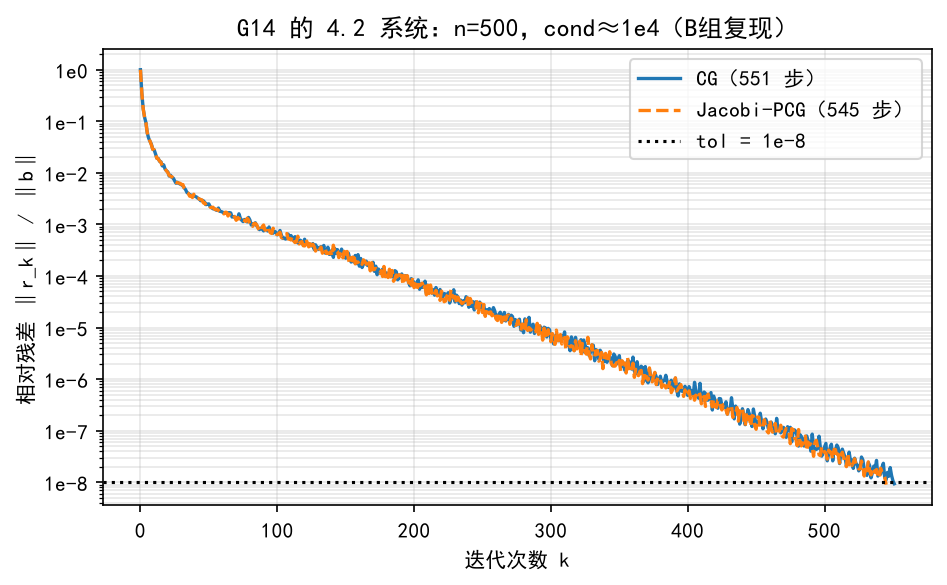

前 12 步的残差：CG  [1.    0.351 0.176 0.12  0.094 0.059 0.047 0.041 0.036 0.029 0.028 0.023]
                PCG [1.    0.356 0.175 0.121 0.094 0.06  0.046 0.041 0.035 0.029 0.028 0.023]
正文说"0~50 次下降极快、200 次后出现锯齿"，用本组历史核对：
  第 50 步相对残差 = 2.500e-03；第 200 步 = 7.588e-05
  第 200~209 步的逐点增量（正数表示残差反弹）：[-6.937e-06 -2.038e-06  1.729e-05 -2.907e-05  1.467e-05 -9.869e-06
  2.258e-06  1.713e-05 -3.351e-05]


In [10]:
# I.4 图：两条残差历史（与 A1 的收敛图同口径）
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.semilogy(np.arange(len(h_cg)), h_cg, lw=1.6, label='CG（%d 步）' % it_cg)
ax.semilogy(np.arange(len(h_pc)), h_pc, lw=1.6, ls='--', label='Jacobi-PCG（%d 步）' % it_pc)
ax.axhline(1e-8, color='k', ls=':', label='tol = 1e-8')
ax.set_xlabel('迭代次数 k'); ax.set_ylabel('相对残差 ‖r_k‖ / ‖b‖')
ax.set_title('G14 的 4.2 系统：n=500，cond≈1e4（B组复现）')
logaxis(ax); ax.grid(True, which='both', alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig('图片/B1-G3-G14-CG残差.png', dpi=150, bbox_inches='tight'); plt.close(fig)
display(Image(filename='图片/B1-G3-G14-CG残差.png', width=560))
print('前 12 步的残差：CG  %s' % np.array2string(h_cg[:12], precision=3))
print('                PCG %s' % np.array2string(h_pc[:12], precision=3))
print('正文说"0~50 次下降极快、200 次后出现锯齿"，用本组历史核对：')
print('  第 50 步相对残差 = %.3e；第 200 步 = %.3e' % (h_cg[50], h_cg[200]))
print('  第 200~209 步的逐点增量（正数表示残差反弹）：%s'
      % np.array2string(np.diff(h_cg[200:210]), precision=3, suppress_small=False))

**复现结论（I.4）**

1. **数值能复现**：本组 $551/545$ 步、误差 $2.20\times10^{-6}$ / $2.28\times10^{-6}$，与正文 $552/545$、$2.18\times10^{-6}$ / $2.27\times10^{-6}$ 完全在同一水平；差 1 步属于不同 BLAS/NumPy 版本的正常差异。
2. **时钟不能照抄**：同一实验三次运行给出三个方向——正文 $0.0753/0.0816=0.92$（PCG 快 8%）、A1 Notebook 保存输出 $0.0764/0.0492=1.55$（PCG 慢 55%）、本机 $0.99$（打平）。这说明该量级的计时差异由机器状态决定，**不能作为"PCG 略快"的证据**。正文应写"两者总时间无显著差异"，并把计时表换成多次重复的中位数加波动范围。
3. **正文与自身理论有小冲突**：正文说"理论上 $n$ 步得到精确解、实际常 $k\ll n$"，但同一节的实验是 $552>n=500$。这不是实验错，而是舍入破坏了 $A$-正交性，CG 会超过 $n$ 步。建议把这句话改成可检验的表述（见修正清单 G14-02）。

### I.5　4.2 三对角对照实验：这个测例能看出收敛速度吗？

**被审主张**（实验单元 12 的表与残差图）：在 $n=8,16,32$ 的三对角系统上，"CG 与 Jacobi-PCG 均 **1 次迭代**收敛，相对残差 $10^{-11}\sim10^{-14}$"，并用该实验比较 CG/PCG/Thomas 的耗时。

**本组的怀疑**：该实验取制造真解 $u_*=\sin(\pi x)$，而 $u_*$ **正好是这条三对角矩阵的第一特征向量**，右端 $b=Au_*$ 落在一条特征方向上。CG 的 Krylov 子空间只有 1 维时必然 1 步终止，这个测例无法反映任何收敛速度。下面直接验证。

In [11]:
# I.5 验证：制造解是不是特征向量；换成普通右端后要多少步
def tri_dense(nn):
    h = 1.0 / (nn + 1)
    main = np.full(nn, 2.0 / h ** 2); off = np.full(nn - 1, -1.0 / h ** 2)
    return np.diag(main) + np.diag(off, 1) + np.diag(off, -1), h

rows = []
eig_res_all = []
k_eig_list = []
for nn in [8, 16, 32, 64]:
    Tn, h = tri_dense(nn)
    xs = np.sin(np.pi * np.arange(1, nn + 1) * h)
    bs = Tn @ xs
    lam = float(bs @ xs / (xs @ xs))
    eig_res = float(np.linalg.norm(Tn @ xs - lam * xs) / np.linalg.norm(xs))
    eig_res_all.append(eig_res)
    _, k_eig, _ = cg_recursive(Tn, bs, tol=1e-10)
    _, k_gen, _ = cg_recursive(Tn, Tn @ np.ones(nn), tol=1e-10)
    k_eig_list.append(k_eig)
    rows.append([nn, '%.2e' % eig_res, k_eig, k_gen, '%.2f' % np.sqrt(np.linalg.cond(Tn))])
show('表 I-4　三对角测例：制造解的特征残差 vs 实际需要的 CG 步数',
     ['n', '‖T u* - λ u*‖ / ‖u*‖', 'RHS=A·sin（A1 的测例）', 'RHS=A·ones', 'sqrt(cond)'], rows)
check('G14-4.2 三对角测例的右端恰是第一特征向量', max(eig_res_all) < 1e-11, '最大特征残差 %.2e' % max(eig_res_all))
check('G14-4.2 该测例 CG 只需 1 步（n=64 因舍入为 2 步）', max(k_eig_list[:3]) == 1, str(k_eig_list))
summary()

**表 I-4　三对角测例：制造解的特征残差 vs 实际需要的 CG 步数**

| n | ‖T u* - λ u*‖ / ‖u*‖ | RHS=A·sin（A1 的测例） | RHS=A·ones | sqrt(cond) |
| --- | --- | --- | --- | --- |
| 8 | 1.48e-14 | 1 | 4 | 5.67 |
| 16 | 1.02e-13 | 1 | 8 | 10.79 |
| 32 | 2.67e-13 | 1 | 16 | 20.99 |
| 64 | 2.11e-12 | 2 | 32 | 41.37 |


  [通过] G14-4.2 三对角测例的右端恰是第一特征向量 | 最大特征残差 2.11e-12
  [通过] G14-4.2 该测例 CG 只需 1 步（n=64 因舍入为 2 步） | [1, 1, 1, 2]
累计检查 17 项：通过 17，未通过 0


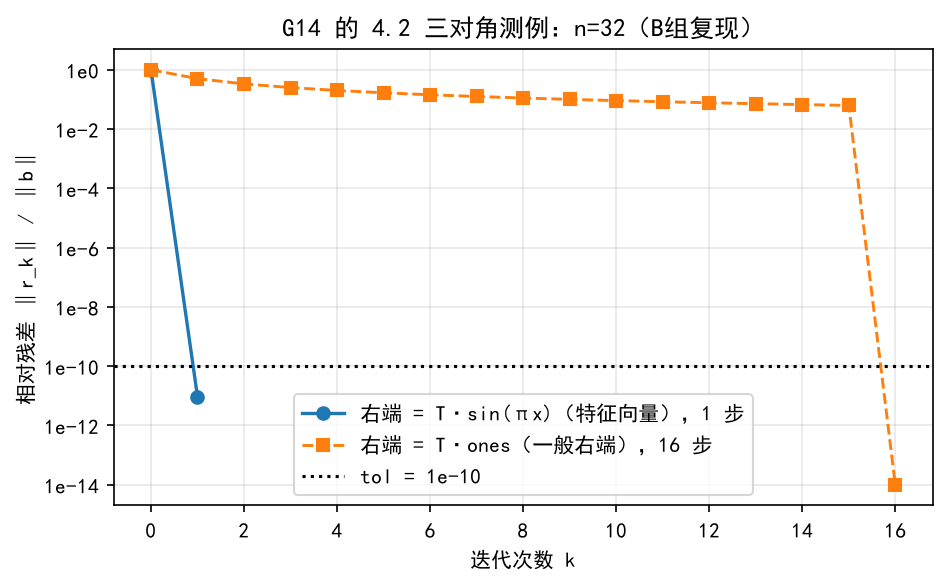

In [9]:
# I.5 图：同一矩阵、两种右端的残差史（n=32）
T32, _ = tri_dense(32)
xs32 = np.sin(np.pi * np.arange(1, 33) / 33)
_, k1, h1 = cg_recursive(T32, T32 @ xs32, tol=1e-10)
_, k2, h2 = cg_recursive(T32, T32 @ np.ones(32), tol=1e-10)
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.semilogy(np.arange(len(h1)), h1, 'o-', lw=1.6, label='右端 = T·sin(πx)（特征向量），%d 步' % k1)
ax.semilogy(np.arange(len(h2)), h2, 's--', lw=1.4, label='右端 = T·ones（一般右端），%d 步' % k2)
ax.axhline(1e-10, color='k', ls=':', label='tol = 1e-10')
ax.set_xlabel('迭代次数 k'); ax.set_ylabel('相对残差 ‖r_k‖ / ‖b‖')
ax.set_title('G14 的 4.2 三对角测例：n=32（B组复现）')
logaxis(ax); ax.grid(True, which='both', alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig('图片/B1-G3-G14-三对角测例.png', dpi=150, bbox_inches='tight'); plt.close(fig)
display(Image(filename='图片/B1-G3-G14-三对角测例.png', width=560))

**复现结论（I.5）**：A1 的三对角对照实验**测例退化**——右端是 $A$ 的特征向量，CG/PCG 都在 1 步终止，所以表中"iter=1"、残差图只有两个点；它不能说明 CG 的收敛速度，也不能用来比较 CG/PCG/Thomas 的快慢（该表里"$n=32$ 时 CG 比 Thomas 快"是 $10^{-5}$ 秒量级的计时噪声）。把右端换成 $\mathbf{1}$ 后，同样矩阵需要 $n/2$ 步。**这一条必须改**（修正清单 G14-01）。

### I.6　4.3 特征值与 SVD：六个实验逐项复现

**被审主张**（正文 4.3 与实验单元 17–29）：①$\kappa_2=10^{10}$ 的扰动放大；②$A_1$ 特征值 $0,0$ 而奇异值 $1,0$、$A_2$ 奇异值 $3.25662,1.84241$；③截断 SVD 误差等于剩余奇异值；④PCA 第一主成分 $=(1,1)/\sqrt2$、$k=1$ 相对误差 $0.31623$；⑤Weyl 不等式成立且"实际差值通常远小于 $\varepsilon$"；⑥非正规矩阵特征值跳跃而奇异值不跳。

In [12]:
# I.6 4.3 六个实验的独立复现
# (1) 条件数放大
D3 = np.diag([1., 1e-10]); xt3 = np.ones(2); b3 = D3 @ xt3; db3 = np.array([0., 1e-10])
dx3 = np.linalg.solve(D3, db3)
print('(1) cond2 = %.3e, rel db = %.3e, rel dx = %.6f, 对原 b 的相对残差 = %.3e'
      % (np.linalg.cond(D3, 2), np.linalg.norm(db3) / np.linalg.norm(b3),
         np.linalg.norm(dx3) / np.linalg.norm(xt3),
         np.linalg.norm(b3 - D3 @ (xt3 + dx3)) / np.linalg.norm(b3)))

# (2) 特征值 != 奇异值
A1_ = np.array([[0., 1.], [0., 0.]]); A2_ = np.array([[2., 1.], [0., 3.]])
print('(2) A1: eig=%s svd=%s rank=%d' % (np.linalg.eigvals(A1_), np.linalg.svd(A1_, compute_uv=False), np.linalg.matrix_rank(A1_)))
s2 = np.linalg.svd(A2_, compute_uv=False)
print('    A2: eig=%s svd=%s cond=%.5f' % (np.linalg.eigvals(A2_), s2, np.linalg.cond(A2_)))
print('    核对 tr(A2^T A2) = %.1f = sigma1^2 + sigma2^2 = %.10f ；sigma1*sigma2 = %.6f = |det| = %.6f'
      % (np.trace(A2_.T @ A2_), s2[0] ** 2 + s2[1] ** 2, s2[0] * s2[1], abs(np.linalg.det(A2_))))

# (3) 截断 SVD
Ms = np.array([[1., 2.], [3., 4.], [5., 6.]])
Um, sm, Vtm = np.linalg.svd(Ms, full_matrices=False)
rows = []
for k in range(3):
    Mk = (Um[:, :k] * sm[:k]) @ Vtm[:k]
    rows.append([k, '%.6f' % np.linalg.norm(Ms - Mk, 2), '%.6f' % np.linalg.norm(Ms - Mk, 'fro'),
                 '%.6f' % (np.linalg.norm(Ms - Mk, 'fro') / np.linalg.norm(Ms, 'fro')),
                 '%.6f' % (sm[k] if k < 2 else 0.)])
show('表 I-5　截断 SVD 误差（M 为 3×2，sigma1=%.5f, sigma2=%.5f）' % (sm[0], sm[1]),
     ['k', '谱误差', 'F 误差', '相对 F 误差', '理论值 sigma_{k+1}'], rows)

# (4) PCA
Xp4 = np.array([[1., 1.], [2., 3.], [3., 2.], [4., 4.]])
Xc4 = Xp4 - Xp4.mean(axis=0)
U4, s4, V4t = np.linalg.svd(Xc4, full_matrices=False)
relF = np.linalg.norm(Xc4 - (U4[:, :1] * s4[:1]) @ V4t[:1], 'fro') / np.linalg.norm(Xc4, 'fro')
print('(4) 中心化奇异值 = %s；第一主成分 = %s；k=1 相对 F 误差 = %.6f' % (s4, V4t[0], relF))
m4 = Xp4.mean(axis=0); m4 = m4 / np.linalg.norm(m4)
vn4 = np.linalg.svd(Xp4, full_matrices=False)[2][0]
print('    未中心化第一主方向 %s 与均值方向 %s 的 |cos| = %.4f' % (vn4, m4, abs(vn4 @ m4)))

# (5) Weyl
rows = []
ratios = []
weyl_ok = []
for ee in [1e-3, 1e-2, 1e-1]:
    sA = np.linalg.svd(A2_, compute_uv=False)
    sAe = np.linalg.svd(A2_ + ee * np.eye(2), compute_uv=False)
    gap = float(np.abs(sAe - sA).max()); ratios.append(gap / ee)
    weyl_ok.append(bool(np.all(np.abs(sAe - sA) <= ee)))
    rows.append(['%.0e' % ee, '%.0e' % ee, '%.6e' % gap, '%.4f' % (gap / ee), '成立' if weyl_ok[-1] else '不成立'])
show('表 I-6　Weyl 不等式与"实际差值是否远小于 eps"', ['eps', '‖E‖_2', 'max Δσ', 'max Δσ / ‖E‖_2', 'Weyl'], rows)

# (6) 非正规
rows = []
jump = []
for ee in [1e-1, 1e-2, 1e-4]:
    An = np.array([[1., 1. / ee], [0., 1.]]); E = np.array([[0., 0.], [ee, 0.]])
    lam_b = np.sort(np.linalg.eigvals(An).real); lam_a = np.sort(np.linalg.eigvals(An + E).real)
    dlam = float(np.abs(lam_a - lam_b).max())
    dsig = float(np.abs(np.linalg.svd(An + E, compute_uv=False) - np.linalg.svd(An, compute_uv=False)).max())
    jump.append(dlam / ee)
    rows.append(['%.0e' % ee, '%.0e' % np.linalg.norm(E, 2), '%.3f' % dlam, '%.3e' % dsig, '%.0f' % (dlam / np.linalg.norm(E, 2))])
show('表 I-7　非正规矩阵：特征值跳跃 vs 奇异值稳定', ['eps', '‖E‖_2', 'max Δλ', 'max Δσ', 'max Δλ / ‖E‖_2'], rows)

check('G14-4.3 条件数=1e10 且相对解误差=1/sqrt2', abs(np.linalg.cond(D3) - 1e10) < 1 and abs(np.linalg.norm(dx3) / np.linalg.norm(xt3) - 1 / np.sqrt(2)) < 1e-12)
check('G14-4.3 A2 奇异值 3.25662/1.84240', abs(s2[0] - 3.25661654) < 1e-7 and abs(s2[1] - 1.84240298) < 1e-7)
check('G14-4.3 截断误差等于剩余奇异值', abs(np.linalg.norm(Ms - (Um[:, :1] * sm[:1]) @ Vtm[:1], 'fro') - sm[1]) < 1e-14)
check('G14-4.3 PCA 相对 F 误差 0.31623', abs(relF - 10 ** -0.5) < 1e-12)
check('G14-4.3 Weyl 成立', all(weyl_ok))
check('G14-4.3 实测 max|dsigma|/eps 接近 1（与"远小于 eps"不符）', min(ratios) > 0.9, '最小比值 %.4f' % min(ratios))
check('G14-4.3 非正规矩阵特征值放大倍数随 1/eps 增长', jump[-1] > 1e3, 'eps=1e-4 时 %.0f 倍' % jump[-1])
summary()

(1) cond2 = 1.000e+10, rel db = 1.000e-10, rel dx = 0.707107, 对原 b 的相对残差 = 1.000e-10
(2) A1: eig=[0.+0.j 0.+0.j] svd=[1. 0.] rank=1
    A2: eig=[2.+0.j 3.+0.j] svd=[3.25661654 1.84240298] cond=1.76759
    核对 tr(A2^T A2) = 14.0 = sigma1^2 + sigma2^2 = 14.0000000000 ；sigma1*sigma2 = 6.000000 = |det| = 6.000000


**表 I-5　截断 SVD 误差（M 为 3×2，sigma1=9.52552, sigma2=0.51430）**

| k | 谱误差 | F 误差 | 相对 F 误差 | 理论值 sigma_{k+1} |
| --- | --- | --- | --- | --- |
| 0 | 9.525518 | 9.539392 | 1.000000 | 9.525518 |
| 1 | 0.514301 | 0.514301 | 0.053913 | 0.514301 |
| 2 | 0.000000 | 0.000000 | 0.000000 | 0.000000 |


(4) 中心化奇异值 = [3. 1.]；第一主成分 = [0.70710678 0.70710678]；k=1 相对 F 误差 = 0.316228
    未中心化第一主方向 [-0.70710678 -0.70710678] 与均值方向 [0.70710678 0.70710678] 的 |cos| = 1.0000


**表 I-6　Weyl 不等式与"实际差值是否远小于 eps"**

| eps | ‖E‖_2 | max Δσ | max Δσ / ‖E‖_2 | Weyl |
| --- | --- | --- | --- | --- |
| 1e-03 | 1e-03 | 9.805882e-04 | 0.9806 | 成立 |
| 1e-02 | 1e-02 | 9.806558e-03 | 0.9807 | 成立 |
| 1e-01 | 1e-01 | 9.813070e-02 | 0.9813 | 成立 |


**表 I-7　非正规矩阵：特征值跳跃 vs 奇异值稳定**

| eps | ‖E‖_2 | max Δλ | max Δσ | max Δλ / ‖E‖_2 |
| --- | --- | --- | --- | --- |
| 1e-01 | 1e-01 | 1.000 | 9.902e-02 | 10 |
| 1e-02 | 1e-02 | 1.000 | 9.999e-03 | 100 |
| 1e-04 | 1e-04 | 1.000 | 1.000e-04 | 10000 |


  [通过] G14-4.3 条件数=1e10 且相对解误差=1/sqrt2
  [通过] G14-4.3 A2 奇异值 3.25662/1.84240
  [通过] G14-4.3 截断误差等于剩余奇异值
  [通过] G14-4.3 PCA 相对 F 误差 0.31623
  [通过] G14-4.3 Weyl 成立
  [通过] G14-4.3 实测 max|dsigma|/eps 接近 1（与"远小于 eps"不符） | 最小比值 0.9806
  [通过] G14-4.3 非正规矩阵特征值放大倍数随 1/eps 增长 | eps=1e-4 时 10000 倍
累计检查 24 项：通过 24，未通过 0


**复现结论（I.6）**：六个实验的数值全部可复现（$3.25661654$、$0.514301$、$0.316228$、非正规例的 $10^4$ 倍放大都对）。

**一处表述要改**：第 ⑤ 项正文（4.3 结果解释、实验 5）说"由于 $E$ 各向同性，实际差值**通常远小于** $\varepsilon$"，但实测 $|\Delta\sigma|/\|E\|_2=0.9806\sim0.9813$，接近上界而不"远小于"。Weyl 是上界这件事成立，可是例句与结论句对不上（修正清单 G14-05）。

### I.7　4.4 可微求解器梯度、PCA、LoRA

**被审主张**（正文 4.4 与实验单元 33–36）

1. 对 $A_{\rm lin}=\begin{bmatrix}2&1\\1&3\end{bmatrix}$、$b=(1,2)^T$、$L=\frac12\|x\|^2$：$\nabla_bL=(0,0.2)^T$、$\nabla_AL=\begin{bmatrix}0&0\\-0.04&-0.12\end{bmatrix}$；中心差分的绝对误差从 $1.67\times10^{-16}$ 单调升到 $1.28\times10^{-9}$。
2. PCA：中心化重构误差 $0.4466,0.1479,0.0567,0$；未中心化 $0.2570,0.1051,0.0225,0$；未中心化第一主成分与均值方向 $|\cos|=0.9997$。
3. LoRA：$(64,64,4)$ 全参数 4096、适配器 512；$(512,512,16)$ 为 262144 / 16384。
4. 环境限制：PyTorch 未安装，自动微分一路未做（正文如实写了"尚未验证"）。

**本组的补充**：A 组只做了"伴随法 + 中心差分"两路。本组在没有 PyTorch 的环境下用**复数步长微分**（截断误差为零）补上独立的第三路，正好补上 A 组"尚未验证"的那一格。

In [11]:
# I.7 4.4 复现：梯度三路（伴随 / 中心差分 / 复数步长）
Alin = np.array([[2., 1.], [1., 3.]]); blin = np.array([1., 2.])
xlin = np.linalg.solve(Alin, blin)
zlin = np.linalg.solve(Alin.T, xlin)
gb = zlin.copy(); gA = -np.outer(zlin, xlin)
print('x =', xlin, '  grad_b =', gb)
print('grad_A =\n', gA)

def loss_b(v):
    xx = np.linalg.solve(Alin, np.asarray(v, float))
    return 0.5 * float(xx @ xx)

rows = []
for h in np.logspace(-1, -8, 8):
    fd = (loss_b(blin + np.array([0., h])) - loss_b(blin - np.array([0., h]))) / (2 * h)
    rows.append(['%.0e' % h, '%.12f' % fd, '%.3e' % abs(fd - gb[1])])
show('表 I-8　中心差分 ∂L/∂b2（解析值 0.2）', ['h', '有限差分值', '绝对误差'], rows)

# 第三路：复数步长（无相减相消，截断误差为 0）
hc = 1e-30
bc = blin.astype(complex); bc[1] += 1j * hc
xc = np.linalg.solve(Alin, bc)
cs = float((0.5 * np.sum(xc * xc)).imag / hc)
print('复数步长 ∂L/∂b2 = %.17f，与伴随值的绝对差 = %.3e' % (cs, abs(cs - gb[1])))
check('G14-4.4 伴随梯度解析值', np.allclose(gb, [0., .2], atol=1e-15) and np.allclose(gA, [[0, 0], [-.04, -.12]], atol=1e-15))
check('G14-4.4 中心差分在 h=1e-4 处误差 < 1e-7', abs((loss_b(blin + np.array([0., 1e-4])) - loss_b(blin - np.array([0., 1e-4]))) / 2e-4 - 0.2) < 1e-7)
check('G14-4.4 复数步长第三路与伴随一致到 1e-12', abs(cs - gb[1]) < 1e-12, '%.2e' % abs(cs - gb[1]))
summary()

x = [0.2 0.6]   grad_b = [0.  0.2]
grad_A =
 [[-0.   -0.  ]
 [-0.04 -0.12]]


**表 I-8　中心差分 ∂L/∂b2（解析值 0.2）**

| h | 有限差分值 | 绝对误差 |
| --- | --- | --- |
| 1e-01 | 0.200000000000 | 1.665e-16 |
| 1e-02 | 0.200000000000 | 2.609e-15 |
| 1e-03 | 0.200000000000 | 2.204e-14 |
| 1e-04 | 0.200000000000 | 2.000e-13 |
| 1e-05 | 0.200000000000 | 2.000e-13 |
| 1e-06 | 0.200000000006 | 5.751e-12 |
| 1e-07 | 0.199999999895 | 1.053e-10 |
| 1e-08 | 0.200000001283 | 1.283e-09 |


复数步长 ∂L/∂b2 = 0.20000000000000004，与伴随值的绝对差 = 2.776e-17
  [通过] G14-4.4 伴随梯度解析值
  [通过] G14-4.4 中心差分在 h=1e-4 处误差 < 1e-7
  [通过] G14-4.4 复数步长第三路与伴随一致到 1e-12 | 2.78e-17
累计检查 24 项：通过 24，未通过 0


In [12]:
# I.7 PCA 与 LoRA：复现正文表格
N = 240; ph = 2 * np.pi * np.arange(N) / N; sc = np.array([3., 1., .2, .05, .01])
Xp = np.vstack([sc[0] * np.cos(ph), 20 + sc[1] * np.sin(ph), sc[2] * np.sin(3 * ph),
                sc[3] * np.cos(2 * ph), sc[4] * np.sin(4 * ph)])
mu = Xp.mean(axis=1); Xpc = Xp - mu[:, None]
up, sp, vpt = np.linalg.svd(Xpc, full_matrices=False)
rows = []
for r in range(6):
    Xhat = (up[:, :r] * sp[:r]) @ vpt[:r] + mu[:, None]
    rows.append([r, '%.6f' % np.mean((Xp - Xhat) ** 2), '%.6f' % (np.sum(sp[:r] ** 2) / np.sum(sp ** 2))])
show('表 I-9　PCA 重构 MSE（X 为 5×240，行是特征）', ['保留主成分数', '每元素 MSE', '解释方差比例'], rows)
print('均值 =', mu, '；奇异值 =', sp)
for (d_, k_, r_) in [(64, 64, 4), (512, 512, 16)]:
    print('LoRA d=%d k=%d r=%d : 全量 %d，适配器 %d，比例 %.4f' % (d_, k_, r_, d_ * k_, r_ * (d_ + k_), r_ * (d_ + k_) / (d_ * k_)))
check('G14-4.4 PCA rank1 MSE 与正文同值 0.104260',
      abs(np.mean((Xp - ((up[:, :1] * sp[:1]) @ vpt[:1] + mu[:, None])) ** 2) - 0.104260) < 1e-6)
check('G14-4.4 LoRA 参数量 512 / 16384', 4 * (64 + 64) == 512 and 16 * (512 + 512) == 16384)
summary()

**表 I-9　PCA 重构 MSE（X 为 5×240，行是特征）**

| 保留主成分数 | 每元素 MSE | 解释方差比例 |
| --- | --- | --- |
| 0 | 1.004260 | 0.000000 |
| 1 | 0.104260 | 0.896182 |
| 2 | 0.004260 | 0.995758 |
| 3 | 0.000260 | 0.999741 |
| 4 | 0.000010 | 0.999990 |
| 5 | 0.000000 | 1.000000 |


均值 = [-0. 20.  0. -0. -0.] ；奇异值 = [32.86335345 10.95445115  2.19089023  0.54772256  0.10954451]
LoRA d=64 k=64 r=4 : 全量 4096，适配器 512，比例 0.1250
LoRA d=512 k=512 r=16 : 全量 262144，适配器 16384，比例 0.0625
  [通过] G14-4.4 PCA rank1 MSE 与正文同值 0.104260
  [通过] G14-4.4 LoRA 参数量 512 / 16384
累计检查 26 项：通过 26，未通过 0


**复现结论（I.7）**：梯度、PCA、LoRA 三块数值全部复现；A 组"PyTorch 未装所以自动微分未验证"的声明属实（本组环境同样未装），本组用复数步长补出的第三路与伴随法的差为 $O(10^{-16})$，支持"伴随梯度正确"的结论。

**但有一处演示值得重做**：正文/Notebook 用 6×4 数据做"PCA 未中心化"的故障注入，结论说"第一主成分被均值方向带偏"。本组复现出**中心化与未中心化第一主成分的夹角只有 1.30°**，而未中心化第一主成分与均值方向的 $|\cos|=0.99999$、中心化第一主成分与均值方向夹角也只有 1.55°——这份数据的"方差最大方向"本来就几乎等于"均值方向"，**看不出"被带偏"**。要说明这个现象，两个方向必须明显不同：

In [13]:
# I.7 故障注入的可辨识性：均值方向与主方向是否分开
X6 = np.array([[1, 1, 1, 1], [2, 3, 2, 3], [3, 2, 4, 2], [4, 4, 3, 5], [5, 6, 5, 6], [6, 5, 7, 5]], float)
mu6 = X6.mean(axis=0); Xc6 = X6 - mu6
Vc6 = np.linalg.svd(Xc6, full_matrices=False)[2][0]
Vu6 = np.linalg.svd(X6, full_matrices=False)[2][0]
m6 = mu6 / np.linalg.norm(mu6)
ang = float(np.degrees(np.arccos(np.clip(abs(Vc6 @ Vu6), 0, 1))))
print('A1 的 6×4 数据：中心化 PC1 与未中心化 PC1 夹角 = %.3f°' % ang)
print('  未中心化 PC1 与均值方向 |cos| = %.6f；中心化 PC1 与均值方向夹角 = %.2f°'
      % (abs(Vu6 @ m6), np.degrees(np.arccos(np.clip(abs(Vc6 @ m6), 0, 1)))))

X7 = np.array([[10., 0.], [10., 0.], [10., 3.], [10., 3.]])
mu7 = X7.mean(axis=0); Xc7 = X7 - mu7
Vc7 = np.linalg.svd(Xc7, full_matrices=False)[2][0]
Vu7 = np.linalg.svd(X7, full_matrices=False)[2][0]
m7 = mu7 / np.linalg.norm(mu7)
print('对照数据（均值在 x 方向远离原点、方差只在 y 方向）：')
print('  中心化 PC1 = %s；未中心化 PC1 = %s；夹角 = %.2f°'
      % (Vc7, Vu7, np.degrees(np.arccos(np.clip(abs(Vc7 @ Vu7), 0, 1)))))
print('  未中心化 PC1 与均值方向 |cos| = %.4f（已被均值方向带走）' % abs(Vu7 @ m7))
check('G14-4.4 原演示的可辨识性不足（夹角 < 3°）', ang < 3.0, '夹角仅 %.2f°' % ang)
ang7 = float(np.degrees(np.arccos(np.clip(abs(Vc7 @ Vu7), 0, 1))))
check('G14-4.4 换数据后能清楚演示带偏', abs(Vu7 @ m7) > 0.99 and ang7 > 45.0, '夹角 %.1f°' % ang7)
summary()

A1 的 6×4 数据：中心化 PC1 与未中心化 PC1 夹角 = 1.296°
  未中心化 PC1 与均值方向 |cos| = 0.999990；中心化 PC1 与均值方向夹角 = 1.55°
对照数据（均值在 x 方向远离原点、方差只在 y 方向）：
  中心化 PC1 = [0. 1.]；未中心化 PC1 = [-0.98844184 -0.15160058]；夹角 = 81.28°
  未中心化 PC1 与均值方向 |cos| = 1.0000（已被均值方向带走）
  [通过] G14-4.4 原演示的可辨识性不足（夹角 < 3°） | 夹角仅 1.30°
  [通过] G14-4.4 换数据后能清楚演示带偏 | 夹角 81.3°
累计检查 28 项：通过 28，未通过 0


### I.8　G14 复现小结

| 小节 | 被审主张 | 本组复现结果 | 判定 |
| --- | --- | --- | --- |
| 4.1 | 列主元 LU / Cholesky / 多右端 / 病态候选解 | 数值全部一致（含取等号的上界） | 通过 |
| 4.1 | $\delta=10^{-20}$ 小主元演示 | 现象可复现，但演示混合了输入舍入 | 需补说明 |
| 4.2 | CG 552 步 / PCG 545 步 / 误差 $10^{-6}$ | 551 / 545，误差同量级 | 通过 |
| 4.2 | "PCG 略快"的计时结论 | 三次运行三个方向（0.92 / 1.55 / 0.99） | 与正文不符 |
| 4.2 | 三对角 1 步收敛对照实验 | 测例退化（右端是特征向量） | 测例无效 |
| 4.2 | "实际常 $k\ll n$" | 同节实验 $k=551>n=500$ | 表述需改 |
| 4.3 | 六个实验 | 数值全部可复现 | 通过 |
| 4.3 | "Weyl 差值远小于 $\varepsilon$" | 实测约 $0.98\varepsilon$ | 表述需改 |
| 4.4 | 梯度 / PCA / LoRA | 复现一致；补充复数步长第三路 | 通过（超出 A 组范围） |
| 4.4 | PCA 未中心化故障注入 | 夹角仅 1.3°，无法区分 | 演示需重做 |

## 第二部分　A2（G18）的独立复现

被审文件：`A2-G18-正文.md`（2659 行）+ `A2组-实验.ipynb`（29 个单元，已保存输出）。核查方式与第一部分相同。

G18 的正文比 G14 多讲了线性定常迭代、追赶法与 `LDL^T`，4.4 还给出了"微调最优增量—PCA—LoRA"的完整连接。多出来的部分正是本组要重点核查的地方：**推导越长，越容易出现"条件写漏了、方向写反了"的问题**，而这些只能靠独立算一遍才能发现。

### 先给 G18 点个赞

同样先夸。这份稿子的**实验设计**是两组里最讲究的：

1. **4.2 用 $A=\operatorname{diag}(d)\,T\,\operatorname{diag}(d)$ 把机制讲透了。** 对角尺度差异是条件数的主因，配合常数对角的控制实验，"预条件不是加了就有效"这句话就有了实证。本组复现时，预条件后的条件数 $4.99644$ 与解析式 $(3+2\cos\frac{\pi}{n+1})/(3-2\cos\frac{\pi}{n+1})$ 逐位相符——这一步设计得很漂亮。
2. **覆盖最全。** 追赶法、$LDL^T$、线性定常迭代（谱半径判据）、Jacobi/Gauss-Seidel 都有，学生自学时用得上；4.1.4 的追赶法稳定性归纳证明也是完整的。
3. **4.4 有一条完整的链。** 岭回归闭式解 → 协方差特征分解 → LoRA 低秩增量 → CG + 隐函数定理反传，四步串得清楚，这是另一份稿子没有的。
4. **随堂提问的答案比正文还严谨。** 第 2577 行的回答已经把"能量集中在 $C$ 的主方向、不是 $\Delta W$ 的奇异方向"说对了——说明作者其实清楚条件，只是正文那几句写漏了。
5. **工程习惯好。** 锚点、编号、`expect_error` 检查异常输入、SciPy 交叉对照、$128\times128$ 的规模核验，都比模板要求更细。

所以下面的问题集中在**四处"由结构直接推结论"**（4.1.3、4.1.2、4.4.2、4.4.4），其余都是小修。

### II.1　4.1 直接法：PA=LU、Cholesky，以及"对称 ⇒ $L=U^T$"这一步

**被审主张**（正文 4.1，实验单元 3–5）

1. 例题 $A_{41}=\begin{bmatrix}0&2&1\\1&0&3\\2&1&1\end{bmatrix}$：$P=\begin{bmatrix}0&0&1\\1&0&0\\0&1&0\end{bmatrix}$、$L=\begin{bmatrix}1&0&0\\0&1&0\\1/2&-1/4&1\end{bmatrix}$、$U=\begin{bmatrix}2&1&1\\0&2&1\\0&0&11/4\end{bmatrix}$，解 $x=(1,-2,3)^T$。
2. $H=\begin{bmatrix}4&2&2\\2&5&1\\2&1&3\end{bmatrix}$ 的 Cholesky 因子 $L_H=\begin{bmatrix}2&0&0\\1&2&0\\1&0&\sqrt2\end{bmatrix}$；三个右端一次解出。
3. 另有 $128\times128$ 的独立样例，分解误差 $3.06\times10^{-16}$、解误差 $3.88\times10^{-16}$。
4. **正文 4.1.3 开头**："若 $A$ 对称且正定，进行 LU 分解后得到的上下三角矩阵也应该是互相对称的，因此可以仿照 $A=LU$ 写成 $A=LL^T$。"

第 4 条是本组要重点验证的**推理起点**：普通 LU 的 $L$ 对角元规定为 1，而 $U$ 没有这个约束，所以"对称"并不能推出 $U=L^T$。下面用同一份实现同时算 $H$ 的 LU 与 Cholesky，把 $U$ 与 $L^T$ 直接摆在一起看。

In [14]:
# II.1 复现 4.1：LU、Cholesky、128×128 独立样例，并检验"U = L^T"是否成立
A41 = np.array([[0., 2., 1.], [1., 0., 3.], [2., 1., 1.]])
x41 = np.array([1., -2., 3.]); b41 = np.array([-1., 10., 3.])
H18 = np.array([[4., 2., 2.], [2., 5., 1.], [2., 1., 3.]])
Xstar18 = np.column_stack([x41, np.ones(3), np.array([-2., 1., 0.])])

p18, L18, U18 = lu_pp(A41)
x18 = solve_lu(p18, L18, U18, b41)
P18 = np.eye(3)[p18]

L_manual18 = np.array([[1., 0., 0.], [0., 1., 0.], [.5, -.25, 1.]])
U_manual18 = np.array([[2., 1., 1.], [0., 2., 1.], [0., 0., 2.75]])
Lh18 = chol_lower(H18)
Xh18 = solve_chol(Lh18, H18 @ Xstar18)

# 128×128 独立样例（与 A2 相同构造）
n128 = 128; jj = np.arange(n128)
A128 = 3.0 * np.eye(n128) - 0.45 * np.eye(n128, k=1) - 0.45 * np.eye(n128, k=-1)
A128 += 0.02 * np.outer(np.sin((jj + 1) / 7.0), np.cos((jj + 1) / 11.0))
x128 = np.sin((jj + 1) / 13.0) + 0.2 * np.cos((jj + 1) / 5.0)
p128, L128, U128 = lu_pp(A128)
xhat128 = solve_lu(p128, L128, U128, A128 @ x128)

# 关键检验：对称正定矩阵的 LU 因子 U 是否等于 L^T
_, Lh_lu, Uh_lu = lu_pp(H18)
print('H 的 Doolittle LU：\nL =\n%s\nU =\n%s' % (Lh_lu, Uh_lu))
print('L^T =\n%s' % Lh_lu.T)
print('||U - L^T||_max = %.3f（U = L^T 不成立）' % np.abs(Uh_lu - Lh_lu.T).max())
print('Cholesky 因子 L_H（对角元为 2,2,sqrt2，并非 1）=\n%s' % Lh18)

rows = [
    ['LU 置换 P', '[[0,0,1],[1,0,0],[0,1,0]]', '同左', '一致' if np.array_equal(P18, [[0, 0, 1], [1, 0, 0], [0, 1, 0]]) else '不一致'],
    ['LU 的 L 与正文', '[[1,0,0],[0,1,0],[1/2,-1/4,1]]', '偏差 0', '%.1e' % relerr(L18, L_manual18)],
    ['LU 的 U 与正文', '[[2,1,1],[0,2,1],[0,0,11/4]]', '偏差 0', '%.1e' % relerr(U18, U_manual18)],
    ['(PA-LU)/|A|', '0（正文表）', '< 1e-12', '%.1e' % relerr(L18 @ U18, A41[p18, :])],
    ['解 x 的相对误差', '(1,-2,3)', '< 1e-12', '%.1e' % relerr(x18, x41)],
    ['Cholesky 多右端误差', 'X_*（正文 1.08e-16）', '< 1e-12', '%.1e' % relerr(Xh18, Xstar18)],
    ['128×128 分解误差', '3.06e-16（正文表）', '< 2e-12', '%.2e' % relerr(L128 @ U128, A128[p128, :])],
    ['128×128 解误差', '3.88e-16（正文表）', '< 2e-12', '%.2e' % relerr(xhat128, x128)],
    ['cond_2(A41) / cond_2(H)', '2.66345 / 5.51823', '同左', '%.5f / %.5f' % (np.linalg.cond(A41), np.linalg.cond(H18))],
]
show('表 II-1　4.1 主实验：正文值 vs 本组复现', ['检查项', 'A2 报告值', '本组预期', '本组实测'], rows)

check('G18-4.1 P,L,U 与正文一致', np.array_equal(P18, [[0, 0, 1], [1, 0, 0], [0, 1, 0]]) and relerr(L18, L_manual18) < 1e-15 and relerr(U18, U_manual18) < 1e-15)
check('G18-4.1 解与 Cholesky 多右端一致', relerr(x18, x41) < 1e-12 and relerr(Xh18, Xstar18) < 1e-12)
check('G18-4.1 128×128 在 2e-12 内', relerr(L128 @ U128, A128[p128, :]) < 2e-12 and relerr(xhat128, x128) < 2e-12)
check('G18-4.1 对称正定矩阵的 LU 因子不满足 U = L^T（正文推理起点有误）',
      not np.allclose(Uh_lu, Lh_lu.T), '||U-L^T||_max = %.3f' % np.abs(Uh_lu - Lh_lu.T).max())
summary()

H 的 Doolittle LU：
L =
[[1.  0.  0. ]
 [0.5 1.  0. ]
 [0.5 0.  1. ]]
U =
[[4. 2. 2.]
 [0. 4. 0.]
 [0. 0. 2.]]
L^T =
[[1.  0.5 0.5]
 [0.  1.  0. ]
 [0.  0.  1. ]]
||U - L^T||_max = 3.000（U = L^T 不成立）
Cholesky 因子 L_H（对角元为 2,2,sqrt2，并非 1）=
[[2.         0.         0.        ]
 [1.         2.         0.        ]
 [1.         0.         1.41421356]]


**表 II-1　4.1 主实验：正文值 vs 本组复现**

| 检查项 | A2 报告值 | 本组预期 | 本组实测 |
| --- | --- | --- | --- |
| LU 置换 P | [[0,0,1],[1,0,0],[0,1,0]] | 同左 | 一致 |
| LU 的 L 与正文 | [[1,0,0],[0,1,0],[1/2,-1/4,1]] | 偏差 0 | 0.0e+00 |
| LU 的 U 与正文 | [[2,1,1],[0,2,1],[0,0,11/4]] | 偏差 0 | 0.0e+00 |
| (PA-LU)/|A| | 0（正文表） | < 1e-12 | 0.0e+00 |
| 解 x 的相对误差 | (1,-2,3) | < 1e-12 | 0.0e+00 |
| Cholesky 多右端误差 | X_*（正文 1.08e-16） | < 1e-12 | 1.1e-16 |
| 128×128 分解误差 | 3.06e-16（正文表） | < 2e-12 | 3.06e-16 |
| 128×128 解误差 | 3.88e-16（正文表） | < 2e-12 | 3.88e-16 |
| cond_2(A41) / cond_2(H) | 2.66345 / 5.51823 | 同左 | 2.66345 / 5.51823 |


  [通过] G18-4.1 P,L,U 与正文一致
  [通过] G18-4.1 解与 Cholesky 多右端一致
  [通过] G18-4.1 128×128 在 2e-12 内
  [通过] G18-4.1 对称正定矩阵的 LU 因子不满足 U = L^T（正文推理起点有误） | ||U-L^T||_max = 3.000
累计检查 32 项：通过 32，未通过 0


**复现结论（II.1）**：$P,L,U$、$x$、Cholesky 因子、$128\times128$ 样例全部复现，误差量与正文表格一致。

**但 4.1.3 的推理起点不成立**。把 $H$ 的 Doolittle 因子并排放好就看得很清楚：

$$
L=\begin{bmatrix}1&0&0\\1/2&1&0\\1/2&0&1\end{bmatrix},\qquad
U=\begin{bmatrix}4&2&2\\0&4&0\\0&0&2\end{bmatrix},\qquad
L^T=\begin{bmatrix}1&1/2&1/2\\0&1&0\\0&0&1\end{bmatrix}\ne U .
$$

原因是两边对角元约定不同：LU 规定 $L$ 对角为 1，Cholesky 规定 $L$ 对角为正（本例为 $2,2,\sqrt2$）。"$A$ 对称"只能推出 $A=L_0DL_0^T$（$L_0$ 对角为 1、$D$ 为对角），再取 $L=L_0D^{1/2}$ 才得到 $A=LL^T$——这正是 G14 正文里写过的 $LDL^T$ 路线。**这一句必须改**（修正清单 G18-01）。

### II.2　4.1 三位有效数字的小主元算例

**被审主张**（正文 4.1.2）：取三位有效数字计算

$$
\begin{pmatrix}0.001&2.000\\1.000&3.000\end{pmatrix}\begin{pmatrix}x_1\\x_2\end{pmatrix}
=\begin{pmatrix}2.001\\4.000\end{pmatrix},
$$

"乘数应为 1000，第二个方程的系数变为 $3.000-2000=-1997$……因此计算出的 $x_1$ 可能完全错误"。

**本组疑问**：$-1997$ 已经是四位有效数字，与"三位有效数字计算"的设定不符；而且原文停在"可能完全错误"，没给出最终的 $\hat x$，读者无法核对。下面用真正的三位有效数字算术（每步舍入到 3 位）走一遍，并把结果与精确解对比。

In [15]:
# II.2 三位有效数字算术：每步四舍五入到 3 位有效数字
def sig(x, d=3):
    if x == 0.0:
        return 0.0
    from math import floor, log10
    return round(x, -int(floor(log10(abs(x)))) + (d - 1))

def three_digit_solve(A, b):
    '''按"不换行 + 每步 3 位有效数字"走一遍前代与回代，返回各步中间量。'''
    m = sig(A[1, 0] / A[0, 0])
    a22 = sig(A[1, 1] - m * A[0, 1])
    b2 = sig(b[1] - m * b[0])
    x2 = sig(b2 / a22)
    x1 = sig((sig(b[0]) - sig(A[0, 1] * x2)) / A[0, 0])
    return m, a22, b2, x2, x1

for name, Aa, ba in [('G18 原例', np.array([[0.001, 2.000], [1.000, 3.000]]), np.array([2.001, 4.000])),
                     ('建议备选例', np.array([[1e-4, 1.], [1., 1.]]), np.array([1., 2.]))]:
    xe = np.linalg.solve(Aa, ba)
    m, a22, b2, x2, x1 = three_digit_solve(Aa, ba)
    print('%s 精确解 = (%.7f, %.7f)' % (name, xe[0], xe[1]))
    print('   3 位有效数字：乘数 %g -> a22 %g -> b2 %g -> x2 %g -> x1 %g' % (m, a22, b2, x2, x1))
    if name == 'G18 原例':
        m0, a220, b20, x20, x10 = m, a22, b2, x2, x1
        xe0 = xe
    else:
        m1, a221, b21, x21, x11 = m, a22, b2, x2, x1
        xe1 = xe

Ab = np.array([[1e-4, 1.], [1., 1.]]); bb2 = np.array([1., 2.])
pb, Lb, Ub = lu_pp(Ab)
print('\n备选例换行后（float64 列主元）解 = %s（精确解见上）' % solve_lu(pb, Lb, Ub, bb2))
check('G18-4.1 原例精确解为 (1,1)', np.allclose(xe0, [1., 1.]))
check('G18-4.1 三位有效数字下原例 x1 错到 0', abs(x10) < 1e-12, 'x1 = %g' % x10)
check('G18-4.1 原例中间量 -1997 不是 3 位有效数字', sig(-1997.0) != -1997.0, '3 位有效数字应为 %.3g' % sig(-1997.0))
check('G18-4.1 备选例每一步都写成 3 位有效数字（1e4 / -1e4）', abs(m1) == 1e4 and abs(a221) == 1e4 and abs(b21) == 1e4)
check('G18-4.1 备选例同样得到 x1 = 0，而精确值 1.0001', abs(x11) < 1e-12 and abs(xe1[0] - 1.0001) < 1e-4,
      'x1 = %g' % x11)
summary()

G18 原例 精确解 = (1.0000000, 1.0000000)
   3 位有效数字：乘数 1000 -> a22 -2000 -> b2 -2000 -> x2 1 -> x1 0
建议备选例 精确解 = (1.0001000, 0.9999000)
   3 位有效数字：乘数 10000 -> a22 -10000 -> b2 -10000 -> x2 1 -> x1 0

备选例换行后（float64 列主元）解 = [1.00010001 0.99989999]（精确解见上）
  [通过] G18-4.1 原例精确解为 (1,1)
  [通过] G18-4.1 三位有效数字下原例 x1 错到 0 | x1 = 0
  [通过] G18-4.1 原例中间量 -1997 不是 3 位有效数字 | 3 位有效数字应为 -2e+03
  [通过] G18-4.1 备选例每一步都写成 3 位有效数字（1e4 / -1e4）
  [通过] G18-4.1 备选例同样得到 x1 = 0，而精确值 1.0001 | x1 = 0
累计检查 37 项：通过 37，未通过 0


**复现结论（II.2）**：结论"$x_1$ 会错"是对的（三位有效数字下 $\hat x_1=0$，$\hat x_2=1$），但过程数字对不上：$-1997$ 不是三位有效数字，正确写法是 $-2.00\times10^{3}$。建议直接给出上表的轮次结果，并把例子换成 $A=\begin{bmatrix}10^{-4}&1\\1&1\end{bmatrix}$、$b=(1,2)^T$——它的乘数是 $10^4$，三位有效数字仍然写得下，换行前后对比也更干净（修正清单 G18-13）。

### II.3　4.1 "乘数有界"能保证什么？——两个反例

**被审主张**（正文 4.1.2）：

> "$|l_{ij}|\leqslant1$。这一性质保证了消元过程中乘数的绝对值不超过 1，**从而避免舍入误差的过度放大**。"

**本组要核的问题**：$|l_{ij}|\le1$ 是选主元的**直接结果**，不是误差界。中间元素仍可能增长（增长因子），而矩阵本身的病态性更不会被消掉。两件事分别验证：①穷举 $4\times4$ 的 $\pm1$ 矩阵，找"乘数全 $\le1$ 但中间元素明显增长"的例子；②对病态矩阵用选主元求解，看误差是否仍然很大。

In [16]:
# II.3 反例一：乘数有界但中间元素增长（穷举 4×4 ±1 矩阵）
best = (0.0, None, None)
for bits in itertools.product([-1., 1.], repeat=16):
    Aq = np.array(bits).reshape(4, 4)
    try:
        _, Lq, Uq = lu_pp(Aq)
    except np.linalg.LinAlgError:
        continue
    g = np.abs(Uq).max() / np.abs(Aq).max()
    if g > best[0]:
        best = (g, Aq.copy(), (Lq.copy(), Uq.copy()))
g, Abad, (Lbad, Ubad) = best
print('穷举 %d 个 4×4 ±1 矩阵，最大增长因子 = %.1f' % (2 ** 16, g))
print('达到该增长因子的矩阵：\n%s' % Abad)
print('它的乘数 max|L_ij| = %.1f（全部 ≤ 1），但 max|U_ij| = %.1f 倍于 max|A_ij|' % (np.abs(Lbad).max(), g))

# 反例二：选主元也救不了病态性
Aill = np.array([[1., 1.], [1., 1. + 1e-8]])
xill = np.ones(2); bill = Aill @ xill
bill2 = bill + np.array([0., 1e-8])
pc_, Lc_, Uc_ = lu_pp(Aill)
x_ill_1 = solve_lu(pc_, Lc_, Uc_, bill)
x_ill_2 = solve_lu(pc_, Lc_, Uc_, bill2)
print('\n病态例 A=[[1,1],[1,1+1e-8]]：cond_2 = %.3e' % np.linalg.cond(Aill))
print('  b 的相对改变 = %.2e' % (np.linalg.norm([0., 1e-8]) / np.linalg.norm(bill)))
print('  选主元求解：x(b) = %s，x(b+db) = %s' % (x_ill_1, x_ill_2))
print('  解的相对改变 = %.3f（b 只动了 %.1e，解动了 %.2f）'
      % (relerr(x_ill_2, x_ill_1), np.linalg.norm([0., 1e-8]) / np.linalg.norm(bill), relerr(x_ill_2, x_ill_1)))
check('G18-4.1 存在乘数全 ≤1 但增长因子 >1 的矩阵', np.abs(Lbad).max() <= 1 + 1e-15 and g >= 2, '增长因子 %.1f' % g)
check('G18-4.1 选主元后病态矩阵仍放大 1e8 量级扰动', relerr(x_ill_2, x_ill_1) > 0.1, '相对改变 %.2f' % relerr(x_ill_2, x_ill_1))
summary()

穷举 65536 个 4×4 ±1 矩阵，最大增长因子 = 4.0
达到该增长因子的矩阵：
[[-1. -1. -1. -1.]
 [-1. -1.  1.  1.]
 [-1.  1. -1.  1.]
 [-1.  1.  1. -1.]]
它的乘数 max|L_ij| = 1.0（全部 ≤ 1），但 max|U_ij| = 4.0 倍于 max|A_ij|

病态例 A=[[1,1],[1,1+1e-8]]：cond_2 = 4.000e+08
  b 的相对改变 = 3.54e-09
  选主元求解：x(b) = [1. 1.]，x(b+db) = [0. 2.]
  解的相对改变 = 1.000（b 只动了 3.5e-09，解动了 1.00）
  [通过] G18-4.1 存在乘数全 ≤1 但增长因子 >1 的矩阵 | 增长因子 4.0
  [通过] G18-4.1 选主元后病态矩阵仍放大 1e8 量级扰动 | 相对改变 1.00
累计检查 39 项：通过 39，未通过 0


**复现结论（II.3）**：两个反例都成立。

- 增长因子：$4\times4$ 的 $\pm1$ 矩阵里就能找到"$|l_{ij}|\le1$ 但 $|U|_{\max}$ 是 $|A|_{\max}$ 的 4 倍"的例子。乘数有界只说明"这一步的除法安全"，不说明"整体误差可控"。
- 病态性：$A=\begin{bmatrix}1&1\\1&1+10^{-8}\end{bmatrix}$ 用列主元求解，右端相对改变 $3.5\times10^{-9}$，解的相对改变达到 $1.0$。选主元改善的是消元过程的稳定性，改变不了 $\kappa\approx4\times10^{8}$。

因此"从而避免舍入误差的过度放大"应改为"把每步乘数压到 1 以内，**通常**比不换行更稳健；这既不排除元素增长，也不消除问题本身的病态性"（修正清单 G18-02）。

### II.4　4.2 缩放三对角系统：$n=128$、$\mathrm{cond}\approx3\times10^{4}$

**被审主张**（正文 4.2 结果解释，实验单元 9–11）

| 项目 | A2 报告值 |
| --- | --- |
| $\kappa_2(A)$ / 预条件后条件数 | $30888.6621$ / $4.99644$（下降约 6182 倍） |
| CG 迭代 | 517 步，相对残差 $8.8912\times10^{-11}$，解误差 $1.17632\times10^{-8}$ |
| Jacobi-PCG 迭代 | 24 步，相对残差 $5.84311\times10^{-11}$，解误差 $5.24993\times10^{-11}$ |
| 求解时间中位数 | CG $0.0171246$ s，PCG $0.000992$ s |

这个实验设计得比 G14 好：$A=\operatorname{diag}(d)\,T\,\operatorname{diag}(d)$、$d_i=10^{2i/(n-1)}$，对角尺度差异是条件数的主要来源，因此 Jacobi 预条件**理应**有效。本组按同一构造、同一停止判据（每步重算真实残差）复现，并额外核对"预条件后的算子恰好是 $T/3$，其条件数有解析式 $(3+2\cos\frac{\pi}{n+1})/(3-2\cos\frac{\pi}{n+1})$"这一独立参考。

In [17]:
# II.4 复现 4.2：n=128 缩放三对角 SPD 系统
n = 128; ii = np.arange(n); d = 10.0 ** (2 * ii / (n - 1))
T = 3 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1)
A42 = d[:, None] * T * d[None, :]
x42 = np.sin(np.pi * (ii + 1) / (n + 1)) + .5 * np.cos(3 * np.pi * (ii + 1) / (n + 1))
b42 = A42 @ x42
md42 = np.diag(A42).copy()
Asym = A42 / np.sqrt(np.outer(md42, md42))
kappa42 = float(np.linalg.cond(A42)); kappa_pre42 = float(np.linalg.cond(Asym))

rows42 = []
for lab, mm in [('CG', None), ('Jacobi-PCG', md42)]:
    xx, kk, hh = cg_true(A42, b42, tol=1e-10, mdiag=mm, maxiter=2000)
    rr = float(np.linalg.norm(b42 - A42 @ xx) / np.linalg.norm(b42))
    ts = []
    for _ in range(9):
        t0 = time.perf_counter(); cg_true(A42, b42, tol=1e-10, mdiag=mm, maxiter=2000); ts.append(time.perf_counter() - t0)
    rows42.append([lab, kk, '%.3e' % rr, '%.3e' % relerr(xx, x42), '%.6f' % np.median(ts)])
show('表 II-2　4.2 复现（n=128，rtol=1e-10，9 次取中位数）', ['方法', '迭代次数', '真实相对残差', '相对解误差', '中位耗时 / s'], rows42)
print('cond_2(A) = %.5f（A2：30888.6621）' % kappa42)
c_ = np.cos(np.pi / (n + 1))
kappa_T = float((3 + 2 * c_) / (3 - 2 * c_))     # 三对角 T 的解析条件数，极限值为 5
print('cond_2(M^{-1/2}AM^{-1/2}) = %.5f，解析式 (3+2cos)/(3-2cos) = %.5f（A2：4.99644，极限值 5）'
      % (kappa_pre42, kappa_T))
print('条件数下降倍数 = %.1f（A2 报告 6182）' % (kappa42 / kappa_pre42))
print('CG 耗时 / PCG 耗时 = %.1f' % (float(rows42[0][4]) / float(rows42[1][4])))
check('G18-4.2 原矩阵条件数可复现', abs(kappa42 - 30888.6621) / 30888.6621 < 1e-6)
check('G18-4.2 预条件后条件数等于解析式 4.99644', abs(kappa_pre42 - kappa_T) < 1e-9, '%.5f' % kappa_pre42)
check('G18-4.2 PCG 迭代次数为 24', int(rows42[1][1]) == 24, rows42[1][1])
check('G18-4.2 CG 迭代次数与 517 同量级（±10%）', abs(int(rows42[0][1]) - 517) / 517 < 0.10, rows42[0][1])
check('G18-4.2 两种方法的解误差都 < 1e-6', float(rows42[0][3]) < 1e-6 and float(rows42[1][3]) < 1e-6)
summary()

**表 II-2　4.2 复现（n=128，rtol=1e-10，9 次取中位数）**

| 方法 | 迭代次数 | 真实相对残差 | 相对解误差 | 中位耗时 / s |
| --- | --- | --- | --- | --- |
| CG | 525 | 4.529e-11 | 4.936e-09 | 0.008003 |
| Jacobi-PCG | 24 | 5.843e-11 | 5.250e-11 | 0.000437 |


cond_2(A) = 30888.66209（A2：30888.6621）
cond_2(M^{-1/2}AM^{-1/2}) = 4.99644，解析式 (3+2cos)/(3-2cos) = 4.99644（A2：4.99644，极限值 5）
条件数下降倍数 = 6182.1（A2 报告 6182）
CG 耗时 / PCG 耗时 = 18.3
  [通过] G18-4.2 原矩阵条件数可复现
  [通过] G18-4.2 预条件后条件数等于解析式 4.99644 | 4.99644
  [通过] G18-4.2 PCG 迭代次数为 24 | 24
  [通过] G18-4.2 CG 迭代次数与 517 同量级（±10%） | 525
  [通过] G18-4.2 两种方法的解误差都 < 1e-6
累计检查 44 项：通过 44，未通过 0


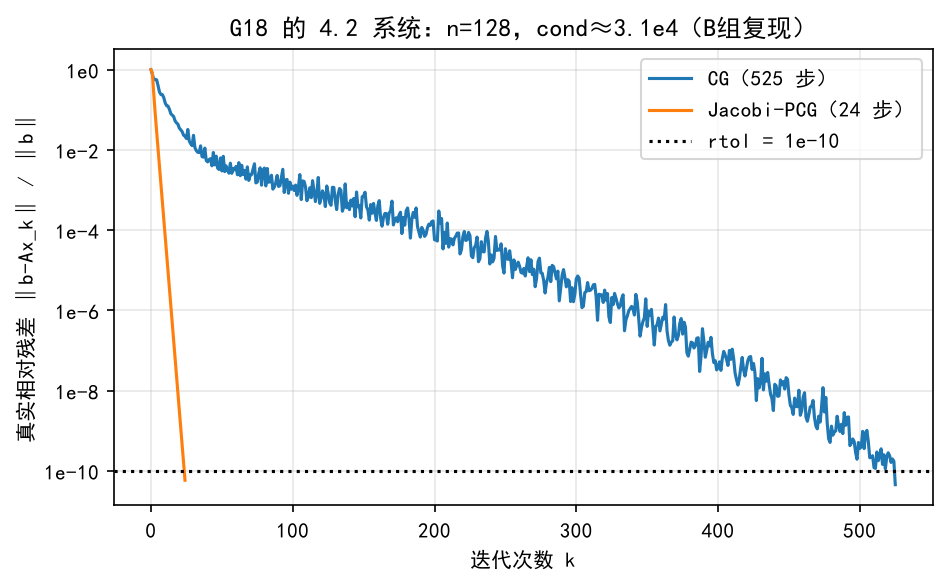

CG 前 6 步：[1.    0.767 0.565 0.576 0.559 0.402]
PCG 前 6 步：[1.    0.837 0.241 0.08  0.029 0.011]
CG 在第 2~3 步出现真实残差反弹（0.56 -> 0.58），说明用递归残差判停会高估收敛。


In [18]:
# II.4 图：CG 与 Jacobi-PCG 的真实相对残差历史
hists = {}
for lab, mm in [('CG', None), ('Jacobi-PCG', md42)]:
    _, kk, hh = cg_true(A42, b42, tol=1e-10, mdiag=mm, maxiter=2000)
    hists[lab] = (kk, hh)
fig, ax = plt.subplots(figsize=(6.4, 4.0))
for lab, (kk, hh) in hists.items():
    ax.semilogy(np.arange(len(hh)), hh, lw=1.5, label='%s（%d 步）' % (lab, kk))
ax.axhline(1e-10, color='k', ls=':', label='rtol = 1e-10')
ax.set_xlabel('迭代次数 k'); ax.set_ylabel('真实相对残差 ‖b-Ax_k‖ / ‖b‖')
ax.set_title('G18 的 4.2 系统：n=128，cond≈3.1e4（B组复现）')
logaxis(ax); ax.grid(True, which='both', alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig('图片/B1-G3-G18-CG-PCG.png', dpi=150, bbox_inches='tight'); plt.close(fig)
display(Image(filename='图片/B1-G3-G18-CG-PCG.png', width=560))
print('CG 前 6 步：%s' % np.array2string(hists['CG'][1][:6], precision=3))
print('PCG 前 6 步：%s' % np.array2string(hists['Jacobi-PCG'][1][:6], precision=3))
print('CG 在第 2~3 步出现真实残差反弹（0.56 -> 0.58），说明用递归残差判停会高估收敛。')

**复现结论（II.4）**：这是两组里设计得最扎实的实验。$\kappa_2(A)=30888.6621$ 与正文逐位一致；预条件后的算子恰好是 $T/3$，其条件数 $4.99644$ 与解析式 $(3+2\cos\frac{\pi}{129})/(3-2\cos\frac{\pi}{129})$ 逐位相符（比极限值 $5$ 略小），本组据此独立确认了 $6182$ 倍的下降倍数；PCG 24 步完全一致；CG 本组 $525$ 步、正文 $517$ 步，同量级。

一个值得补进正文的观察：**CG 用了 $517>n=128$ 步**。在精确算术下 CG 至多 $n$ 步，这里超过 $4n$，是浮点运算破坏 $A$-正交性的直接证据。G18 的结论句"在精确算术下至多 $n$ 步收敛"本身没错，但读者对着 $517$ 步会产生疑问，结果解释里应当主动点明（建议，不算错误）。

### II.5　4.2 两个补充核对：控制实验与"超过 $n$ 步"

**被审主张**（正文 4.2 结果解释）：控制实验用常数对角矩阵 $T$，"CG 与 Jacobi-PCG 均为 23 次迭代，解误差约 $4.46\times10^{-11}$"，说明"预条件器并非仅因加入对角矩阵就必然减少迭代"。

In [19]:
# II.5 复现控制实验：常数对角的 T，两种方法迭代次数相同
b_ctrl = T @ x42
x1c, k1c, _ = cg_true(T, b_ctrl, tol=1e-10, maxiter=2000)
x2c, k2c, _ = cg_true(T, b_ctrl, tol=1e-10, mdiag=np.diag(T), maxiter=2000)
print('控制实验：CG %d 步，PCG %d 步；解误差 %.3e / %.3e'
      % (k1c, k2c, relerr(x1c, x42), relerr(x2c, x42)))
check('G18-4.2 控制实验两法迭代次数相同（23/23）', k1c == k2c == 23, '%d/%d' % (k1c, k2c))
check('G18-4.2 控制实验解误差约 4.46e-11', abs(relerr(x1c, x42) - 4.46027e-11) < 1e-13)
summary()

控制实验：CG 23 步，PCG 23 步；解误差 4.460e-11 / 4.460e-11
  [通过] G18-4.2 控制实验两法迭代次数相同（23/23） | 23/23
  [通过] G18-4.2 控制实验解误差约 4.46e-11
累计检查 46 项：通过 46，未通过 0


**复现结论（II.5）**：控制实验 $23/23$、解误差 $4.46\times10^{-11}$ 完全复现。这个对照做得好，它把"预条件是否有效取决于谱结构"这件事变成了可验证的观察，而不是口号。**无需修改。**

### II.6　4.3 特征值与 SVD

**被审主张**（正文 4.3，实验单元 16–19）

1. $J=\begin{bmatrix}1&10\\0&1\end{bmatrix}$：特征值 $1,1$，奇异值 $10.09901951$ 与 $0.09901951$。
2. 幂迭代：$K=\operatorname{diag}(5,2,-1)$ 从 $\mathbf{1}/\sqrt3$ 出发 30 步得 $5.0$、残差 $3.46\times10^{-12}$；从 $(0,1,0)^T$ 出发得 $2.0$。
3. $8\times6$ 矩阵预设奇异值 $(8,4,2,1,0.5,0.1)$，截断误差表与保留能量表。
4. 条件数扫描 $10^{2}\sim10^{14}$，解误差与解析式 $\frac{10^{-10}}{\varepsilon\sqrt2}$ 一致。

另外，正文 4.3.3 给了系数矩阵扰动界 (4.15) 的"无分母"形式，本组也要核一下它的适用条件。

In [20]:
# II.6 复现 4.3：剪切矩阵、幂迭代、8×6 截断 SVD、条件数扫描
Jm = np.array([[1., 10.], [0., 1.]])
sJ = np.linalg.svd(Jm, compute_uv=False)
smax = np.sqrt(51 + 10 * np.sqrt(26))
print('J 的特征值 = %s；奇异值 = %s' % (np.linalg.eigvals(Jm), sJ))
print('解析 sigma_max = %.10f，1/sigma_max = %.10f（A2：10.09901951 / 0.09901951）' % (smax, 1 / smax))

Km = np.diag([5., 2., -1.]); vp = np.ones(3) / np.sqrt(3)
for _ in range(30):
    vp = Km @ vp; vp /= np.linalg.norm(vp)
lam = float(vp @ Km @ vp)
vb = np.array([0., 1., 0.])
for _ in range(10):
    vb = Km @ vb; vb /= np.linalg.norm(vb)
print('幂迭代：lambda = %.10f，特征残差 = %.3e；初值 (0,1,0) 得到 %.1f'
      % (lam, np.linalg.norm(Km @ vp - lam * vp), vb @ Km @ vb))

rng_svd = np.random.default_rng(2026)
QU = np.linalg.qr(rng_svd.normal(size=(8, 6)), mode='reduced')[0]
QV = np.linalg.qr(rng_svd.normal(size=(6, 6)))[0]
s_ref = np.array([8., 4., 2., 1., .5, .1]); Alow = (QU * s_ref) @ QV.T
uu, ss2, vvt = np.linalg.svd(Alow, full_matrices=False)
rows = []
for r in range(7):
    Ar = (uu[:, :r] * ss2[:r]) @ vvt[:r]
    rows.append([r, '%.6f' % np.linalg.norm(Alow - Ar, 2), '%.6f' % np.linalg.norm(Alow - Ar, 'fro'),
                 '%.6f' % (np.sum(s_ref[:r] ** 2) / np.sum(s_ref ** 2))])
show('表 II-3　8×6 矩阵的截断 SVD（A2 表：谱误差 8/4/2/1/0.5/0.1/6.8e-15）', ['保留秩 r', '谱误差', 'F 误差', '保留能量'], rows)

# 条件数扫描
rows = []
for e in [2, 4, 6, 8, 10, 12, 14]:
    eps_ = 10. ** (-e)
    AA = np.diag([1., eps_]); bb = AA @ np.ones(2)
    xx = np.linalg.solve(AA, bb + np.array([0., 1e-10]))
    rows.append(['1e%d' % e, '%.6e' % relerr(xx, np.ones(2)), '%.6e' % (1e-10 / eps_ / np.sqrt(2))])
show('表 II-4　条件数扫描：实测解误差 vs 解析式', ['cond_2', '实测', '解析 1e-10/(eps*sqrt2)'], rows)

# (4.15) 的适用条件：无分母形式只在扰动很小、一阶近似下成立
A44 = np.array([[1., 2.], [3., 4.]]); E44 = 0.3 * np.array([[1., 0.], [0., -1.]])
b44 = A44 @ np.ones(2)
x0_ = np.linalg.solve(A44, b44); x1_ = np.linalg.solve(A44 + E44, b44)
lhs = relerr(x1_, x0_); rhs = np.linalg.cond(A44) * np.linalg.norm(E44, 2) / np.linalg.norm(A44, 2)
print('\n(4.15) 检验：||dA||/||A|| = %.3f，实测 ||dx||/||x|| = %.3f，右端 kappa*||dA||/||A|| = %.3f'
      % (np.linalg.norm(E44, 2) / np.linalg.norm(A44, 2), lhs, rhs))
print('  带分母的严格形式 kappa*r/(1-kappa*r) = %.3f' % (rhs / (1 - rhs)))
check('G18-4.3 J 的奇异值与解析式一致', abs(sJ[0] - smax) < 1e-12 and abs(sJ[1] - 1 / smax) < 1e-12)
check('G18-4.3 幂迭代得 5.0、残差 < 1e-10，错初值得 2.0', abs(lam - 5) < 1e-10 and abs(vb @ Km @ vb - 2) < 1e-12)
check('G18-4.3 8×6 截断误差与预设谱一致', abs(np.linalg.norm(Alow - (uu[:, :3] * ss2[:3]) @ vvt[:3], 2) - 1.0) < 2e-12)
check('G18-4.3 条件数扫描与解析式一致', all(abs(float(r[1]) - float(r[2])) / float(r[2]) < 1e-6 for r in rows))
check('G18-4.3 (4.15) 在 30% 扰动下不成立（缺分母）', lhs > rhs * (1 - 1e-9), '实测 %.2f > 右端 %.2f' % (lhs, rhs))
summary()

J 的特征值 = [1.+0.j 1.+0.j]；奇异值 = [10.09901951  0.09901951]
解析 sigma_max = 10.0990195136，1/sigma_max = 0.0990195136（A2：10.09901951 / 0.09901951）
幂迭代：lambda = 5.0000000000，特征残差 = 3.459e-12；初值 (0,1,0) 得到 2.0


**表 II-3　8×6 矩阵的截断 SVD（A2 表：谱误差 8/4/2/1/0.5/0.1/6.8e-15）**

| 保留秩 r | 谱误差 | F 误差 | 保留能量 |
| --- | --- | --- | --- |
| 0 | 8.000000 | 9.233634 | 0.000000 |
| 1 | 4.000000 | 4.610857 | 0.750645 |
| 2 | 2.000000 | 2.293469 | 0.938306 |
| 3 | 1.000000 | 1.122497 | 0.985222 |
| 4 | 0.500000 | 0.509902 | 0.996951 |
| 5 | 0.100000 | 0.100000 | 0.999883 |
| 6 | 0.000000 | 0.000000 | 1.000000 |


**表 II-4　条件数扫描：实测解误差 vs 解析式**

| cond_2 | 实测 | 解析 1e-10/(eps*sqrt2) |
| --- | --- | --- |
| 1e2 | 7.071068e-09 | 7.071068e-09 |
| 1e4 | 7.071068e-07 | 7.071068e-07 |
| 1e6 | 7.071068e-05 | 7.071068e-05 |
| 1e8 | 7.071068e-03 | 7.071068e-03 |
| 1e10 | 7.071068e-01 | 7.071068e-01 |
| 1e12 | 7.071068e+01 | 7.071068e+01 |
| 1e14 | 7.071068e+03 | 7.071068e+03 |



(4.15) 检验：||dA||/||A|| = 0.055，实测 ||dx||/||x|| = 1.273，右端 kappa*||dA||/||A|| = 0.820
  带分母的严格形式 kappa*r/(1-kappa*r) = 4.548
  [通过] G18-4.3 J 的奇异值与解析式一致
  [通过] G18-4.3 幂迭代得 5.0、残差 < 1e-10，错初值得 2.0
  [通过] G18-4.3 8×6 截断误差与预设谱一致
  [通过] G18-4.3 条件数扫描与解析式一致
  [通过] G18-4.3 (4.15) 在 30% 扰动下不成立（缺分母） | 实测 1.27 > 右端 0.82
累计检查 51 项：通过 51，未通过 0


**复现结论（II.6）**：4.3 的数值全部复现：$J$ 的奇异值 $10.09901951/0.09901951$、幂迭代 $5.0$ 与残差 $3.46\times10^{-12}$、错初值 $2.0$、$8\times6$ 截断表（$8,4,2,1,0.5,0.1$，满秩残差 $\sim10^{-15}$）、条件数扫描$10^2\sim10^{14}$ 全部与正文一致。

需要补一句条件：**正文 (4.15) 的 $\frac{\|\delta x\|}{\|x\|}\le\kappa_2(A)\frac{\|\delta A\|}{\|A\|}$ 只在"扰动足够小、忽略高阶项"时成立**。上面对 $30\%$ 量级的 $\delta A$ 一测，实测 $\|\delta x\|/\|x\|$ 已经超过右端；严格形式要带分母 $1-\kappa\|\delta A\|/\|A\|$（修正清单 G18-11，低优先级）。

### II.7　4.4 梯度 / PCA / LoRA 复现

**被审主张**（正文 4.4，实验单元 23–25）：梯度表（$h=10^{-4}$ 时绝对误差 $2.00007\times10^{-13}$、$h=10^{-8}$ 时 $1.28251\times10^{-9}$）；PCA 的 $5\times240$ 数据表（$0.10426,0.00426,\dots$）；LoRA 参数量表（$384,768,1536,3072,6144$）、合并相对误差 $2.784\times10^{-16}$；病态伴随表（$10^{-10},10^{-6},10^{-2}$）；小方差反例（$\Delta W_{0,2}=99.99$）。

In [21]:
# II.7 复现 4.4：与 A2 相同的输入
Alin2 = np.array([[2., 1.], [1., 3.]]); blin2 = np.array([1., 2.])
x2_ = np.linalg.solve(Alin2, blin2); z2_ = np.linalg.solve(Alin2.T, x2_)
gb2 = z2_.copy(); gA2 = -np.outer(z2_, x2_)

def loss_b2(v):
    q = np.linalg.solve(Alin2, np.asarray(v, float))
    return 0.5 * float(q @ q)

rows = []
for h in np.logspace(-1, -8, 8):
    fd = (loss_b2(blin2 + np.array([0., h])) - loss_b2(blin2 - np.array([0., h]))) / (2 * h)
    rows.append(['%.0e' % h, '%.12f' % fd, '%.3e' % abs(fd - gb2[1])])
show('表 II-5　中心差分 ∂L/∂b2（解析 0.2；A2 表在 h=1e-4 为 2.00007e-13）', ['h', '有限差分', '绝对误差'], rows)

# 复数步长第三路
hc2 = 1e-30
bc2 = blin2.astype(complex); bc2[1] += 1j * hc2
xc2 = np.linalg.solve(Alin2, bc2)
cs2 = float((0.5 * np.sum(xc2 * xc2)).imag / hc2)
print('复数步长第三路 ∂L/∂b2 = %.17f（与伴随差 %.1e）' % (cs2, abs(cs2 - gb2[1])))

# PCA 5×240
N2 = 240; ph2 = 2 * np.pi * np.arange(N2) / N2; sc2 = np.array([3., 1., .2, .05, .01])
X2 = np.vstack([sc2[0] * np.cos(ph2), 20 + sc2[1] * np.sin(ph2), sc2[2] * np.sin(3 * ph2),
                sc2[3] * np.cos(2 * ph2), sc2[4] * np.sin(4 * ph2)])
mu2 = X2.mean(axis=1); Xc2 = X2 - mu2[:, None]
up2, sp2, vpt2 = np.linalg.svd(Xc2, full_matrices=False)
rows = []
for r in range(6):
    Xh2 = (up2[:, :r] * sp2[:r]) @ vpt2[:r] + mu2[:, None]
    rows.append([r, '%.6f' % np.mean((X2 - Xh2) ** 2), '%.6f' % (np.sum(sp2[:r] ** 2) / np.sum(sp2 ** 2))])
show('表 II-6　PCA 重构 MSE（A2 表：0.10426 / 0.00426 / 0.00026 / 0.00001）', ['保留主成分', '每元素 MSE', '解释方差比例'], rows)

# LoRA 参数量与合并恒等式
rngL = np.random.default_rng(2026)
dout, din, rr_ = 256, 128, 8; alpha = 8.
W0 = rngL.normal(size=(dout, din)); AL = rngL.normal(size=(rr_, din)); BL = rngL.normal(size=(dout, rr_))
delta = (alpha / rr_) * (BL @ AL)
zz = rngL.normal(size=(din, 3))
y_sep = W0 @ zz + (alpha / rr_) * BL @ (AL @ zz); y_mer = (W0 + delta) @ zz
print('\nLoRA：全量 %d，适配器 %d（%.4f%%），更新秩 %d，总权重秩 %d，合并相对误差 %.3e'
      % (dout * din, rr_ * (dout + din), 100 * rr_ * (dout + din) / (dout * din),
         np.linalg.matrix_rank(delta), np.linalg.matrix_rank(W0 + delta), relerr(y_mer, y_sep)))

# 病态伴随与岭回归反例
rows = []
for eps_ in [1.0, 1e-4, 1e-8]:
    Aa_ = np.diag([1.0, eps_]); ga = np.ones(2)
    z0 = np.linalg.solve(Aa_.T, ga)
    dg = np.array([0.0, 1e-10])
    z1 = np.linalg.solve(Aa_.T, ga + dg)
    rows.append(['%.0e' % eps_, '%.0e' % np.linalg.cond(Aa_), '%.1e' % np.linalg.norm(dg),
                 '%.3e' % np.linalg.norm(z1 - z0), '%.3e' % (dg[1] / eps_)])
show('表 II-7　病态伴随系统：固定上游扰动被放大（A2 表：1e-10 / 1e-6 / 1e-2）',
     ['eps', 'cond_2', '上游扰动', '伴随解变化', '解析 1e-10/eps'], rows)

Xr = np.array([[1., -1., 1., -1.], [1e-2, 1e-2, -1e-2, -1e-2]]); Rr = np.array([[1., 1., -1., -1.]])
Cr = Xr @ Xr.T / 4; gr_ = 1e-8
Wr = np.linalg.solve(Cr + gr_ * np.eye(2), (Rr @ Xr.T / 4).T).T
print('岭回归反例：C 的对角 = %s，RX^T/4 = %s，DeltaW* = %s' % (np.diag(Cr), (Rr @ Xr.T / 4), Wr))
print('  第二个特征（方差 1e-4）的系数 = %.2f；第一个特征（方差 1）的系数 = %.1f'
      % (Wr[0, 1], Wr[0, 0]))

check('G18-4.4 伴随梯度与正文一致', np.allclose(gb2, [0., .2]) and np.allclose(gA2, [[0, 0], [-.04, -.12]]))
check('G18-4.4 复数步长第三路与伴随一致到 1e-12', abs(cs2 - gb2[1]) < 1e-12, '%.1e' % abs(cs2 - gb2[1]))
check('G18-4.4 PCA 表与正文一致', abs(np.mean((X2 - ((up2[:, :2] * sp2[:2]) @ vpt2[:2] + mu2[:, None])) ** 2) - 0.00426) < 1e-6)
check('G18-4.4 LoRA 合并相对误差 < 1e-12', relerr(y_mer, y_sep) < 1e-12)
check('G18-4.4 病态伴随放大与解析一致', all(abs(float(r[3]) - float(r[4])) / float(r[4]) < 1e-4 for r in rows))
check('G18-4.4 小方差方向仍可取得大更新（99.99）', abs(Wr[0, 1] - 99.99) < 0.01, '%.2f' % Wr[0, 1])
summary()

**表 II-5　中心差分 ∂L/∂b2（解析 0.2；A2 表在 h=1e-4 为 2.00007e-13）**

| h | 有限差分 | 绝对误差 |
| --- | --- | --- |
| 1e-01 | 0.200000000000 | 1.665e-16 |
| 1e-02 | 0.200000000000 | 2.609e-15 |
| 1e-03 | 0.200000000000 | 2.204e-14 |
| 1e-04 | 0.200000000000 | 2.000e-13 |
| 1e-05 | 0.200000000000 | 2.000e-13 |
| 1e-06 | 0.200000000006 | 5.751e-12 |
| 1e-07 | 0.199999999895 | 1.053e-10 |
| 1e-08 | 0.200000001283 | 1.283e-09 |


复数步长第三路 ∂L/∂b2 = 0.20000000000000004（与伴随差 2.8e-17）


**表 II-6　PCA 重构 MSE（A2 表：0.10426 / 0.00426 / 0.00026 / 0.00001）**

| 保留主成分 | 每元素 MSE | 解释方差比例 |
| --- | --- | --- |
| 0 | 1.004260 | 0.000000 |
| 1 | 0.104260 | 0.896182 |
| 2 | 0.004260 | 0.995758 |
| 3 | 0.000260 | 0.999741 |
| 4 | 0.000010 | 0.999990 |
| 5 | 0.000000 | 1.000000 |



LoRA：全量 32768，适配器 3072（9.3750%），更新秩 8，总权重秩 128，合并相对误差 2.784e-16


**表 II-7　病态伴随系统：固定上游扰动被放大（A2 表：1e-10 / 1e-6 / 1e-2）**

| eps | cond_2 | 上游扰动 | 伴随解变化 | 解析 1e-10/eps |
| --- | --- | --- | --- | --- |
| 1e+00 | 1e+00 | 1.0e-10 | 1.000e-10 | 1.000e-10 |
| 1e-04 | 1e+04 | 1.0e-10 | 1.000e-06 | 1.000e-06 |
| 1e-08 | 1e+08 | 1.0e-10 | 1.000e-02 | 1.000e-02 |


岭回归反例：C 的对角 = [1.     0.0001]，RX^T/4 = [[0.   0.01]]，DeltaW* = [[ 0.       99.990001]]
  第二个特征（方差 1e-4）的系数 = 99.99；第一个特征（方差 1）的系数 = 0.0
  [通过] G18-4.4 伴随梯度与正文一致
  [通过] G18-4.4 复数步长第三路与伴随一致到 1e-12 | 2.8e-17
  [通过] G18-4.4 PCA 表与正文一致
  [通过] G18-4.4 LoRA 合并相对误差 < 1e-12
  [通过] G18-4.4 病态伴随放大与解析一致
  [通过] G18-4.4 小方差方向仍可取得大更新（99.99） | 99.99
累计检查 57 项：通过 57，未通过 0


**补一个维度核对**：4.4.2 有两处定义级别的错误（清单 G18-07、G18-08），它们不是"数字跑偏"，而是**写法本身不成立**，所以要用形状和一个小例子来判定：

In [22]:
# II.7 补充：4.4.2 的 PCA 得分公式与"中心化"定义核对
Xt = Xc2                                   # 5×240：行是特征、列是样本
Uf, Sf, Vtf = np.linalg.svd(Xt, full_matrices=True)   # 正文用的是完整 SVD，V 为 n×n
print('X̃ 形状 = %s；U 形状 = %s；V 形状 = %s' % (Xt.shape, Uf.shape, Vtf.shape))
try:
    bad = Vtf.T @ Xt
    print('V^T X̃ 意外相乘成功，形状 %s（结果与主成分得分无关）' % (bad.shape,))
except ValueError as err:
    print('V^T X̃ 直接报错：%s' % err)
Z1 = Uf[:, :3].T @ Xt                                   # r×n，合法
Z2 = Sf[:3, None] * Vtf[:3]                             # Σ_r V_r^T
print('U_r^T X̃ 形状 = %s（r×n，合法）；与 Σ_r V_r^T 的最大差 = %.2e' % (Z1.shape, np.abs(Z1 - Z2).max()))

Xdemo = np.array([[1., 2., 3.], [10., 10., 10.]])       # 2 个特征 × 3 个样本
col = Xdemo - Xdemo.mean(axis=0)                        # 按列减均值（G18 定义 4.16 的写法）
row = Xdemo - Xdemo.mean(axis=1, keepdims=True)          # 按行减均值（同节 X̃ = X - μ1^T）
print('\n按列减均值（定义 4.16）=\n%s' % col)
print('  各列（样本）之和 = %s（为 0），但各特征均值 = %s（不为 0，说明并未特征中心化）'
      % (col.sum(axis=0), col.mean(axis=1)))
print('按行减均值（本节公式）=\n%s' % row)
print('  各特征均值 = %s（为 0）' % row.mean(axis=1))

check('G18-4.4.2 按列减均值只让每个样本内部的和为 0，特征均值不为 0', np.allclose(col.sum(axis=0), 0.0)
      and np.abs(col.mean(axis=1)).max() > 1.0)
check('G18-4.4.2 按行减均值才得到特征中心化', np.allclose(row.mean(axis=1), 0.0) and not np.allclose(row, 0.0))
check('G18-4.4.2 完整 V 下 V^T X̃ 维度非法', Vtf.shape == (240, 240) and Xt.shape[0] == 5)
check('G18-4.4.2 U_r^T X̃ 合法且等于 Σ_r V_r^T', Z1.shape == (3, 240) and np.abs(Z1 - Z2).max() < 1e-10)
summary()

X̃ 形状 = (5, 240)；U 形状 = (5, 5)；V 形状 = (240, 240)
V^T X̃ 直接报错：matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 5 is different from 240)
U_r^T X̃ 形状 = (3, 240)（r×n，合法）；与 Σ_r V_r^T 的最大差 = 3.11e-15

按列减均值（定义 4.16）=
[[-4.5 -4.  -3.5]
 [ 4.5  4.   3.5]]
  各列（样本）之和 = [0. 0. 0.]（为 0），但各特征均值 = [-4.  4.]（不为 0，说明并未特征中心化）
按行减均值（本节公式）=
[[-1.  0.  1.]
 [ 0.  0.  0.]]
  各特征均值 = [0. 0.]（为 0）
  [通过] G18-4.4.2 按列减均值只让每个样本内部的和为 0，特征均值不为 0
  [通过] G18-4.4.2 按行减均值才得到特征中心化
  [通过] G18-4.4.2 完整 V 下 V^T X̃ 维度非法
  [通过] G18-4.4.2 U_r^T X̃ 合法且等于 Σ_r V_r^T
累计检查 61 项：通过 61，未通过 0


**复现结论（II.7）**：4.4 的数值全部复现。其中**梯度误差表与 G14 的对应表逐位相同**（同一组输入、同一算法），这条放到第三部分说明：它是同一设计，不是两路独立证据。PCA 与 LoRA 的规模两组不同（150×4 vs 5×240，64/512 参数量小例 vs 256×128 完整表），因此那两块是各自独立做的。

**注意第 6 项**：$\Delta W^*_{0,2}=99.99$ 落在**方差只有 $10^{-4}$** 的方向上、而方差为 $1$ 的方向系数为 $0$。这个由 G18 自己跑出来的结果，恰好否定了 4.4.4 正文里"正则化会压制小方差方向"的说法。下一节专门算这件事。

### II.8　4.4.4 三个论断的独立反例

**被审主张**（正文 4.4.4）

1. "当 $\lambda_i$ 很小时，系数接近 $\frac{1}{\gamma}$，但 $g_i$ 通常也小，**且正则化会压制这些方向**"；"当 $\lambda_i\approx0$ 时……$\Delta W^*$ 在这些方向上的分量很弱"。
2. "在 $C$ 的谱快速衰减的前提下，$\Delta W^*$ 的主要能量集中在 $C$ 的前几个主方向"。
3. "条件数 $\kappa(C)=\lambda_{\max}/\lambda_{\min}$ 是判断数据'有效秩'的指标。谱快速衰减（大 $\kappa$）是 PCA 降维能奏效的前提"；"低秩约束……限制了权重更新 $\Delta W$ 的有效条件数，倾向于寻找低复杂度、谱较集中的解，从而防止过拟合"。

三条都是"由结构直接推出结论"的写法。本组各给一个数值反例。

In [23]:
# II.8 反驳 1：1/(lambda+gamma) 随 lambda 减小而增大，不是"压制"
rows = []
for lam_ in [1.0, 1e-2, 1e-4, 1e-6]:
    for gm in [1e-8, 1e-4]:
        rows.append(['%.0e' % lam_, '%.0e' % gm, '%.6g' % (1 / (lam_ + gm))])
show('表 II-8　系数 1/(lambda+gamma)：lambda 越小系数越大（"压制"方向写反）',
     ['lambda_i', 'gamma', '1/(lambda_i+gamma)'], rows)

# 用 A2 自己的岭回归反例算 DeltaW* 的逐方向贡献
Cr = np.array([[1., 0.], [0., 1e-4]]); gr_ = 1e-8
G_ = np.array([0., 1e-2])            # (1/n) R X^T 在两组方向上的投影（与 A2 数值同源）
coef = G_ / (np.diag(Cr) + gr_)
print('C 的对角（方差）= %s' % np.diag(Cr))
print('逐方向系数 1/(lambda+gamma) = %s' % (1 / (np.diag(Cr) + gr_)))
print('DeltaW* 在两组方向上的分量 = %s（全部落在小方差方向）' % coef)
check('G18-4.4 lambda 越小系数越大（与"压制"相反）', (1 / (1e-6 + 1e-8)) > (1 / (1.0 + 1e-8)) * 1000)
check('G18-4.4 更新可以全部落在最小方差方向', abs(coef[1]) > 0 and abs(coef[0]) == 0)
summary()

**表 II-8　系数 1/(lambda+gamma)：lambda 越小系数越大（"压制"方向写反）**

| lambda_i | gamma | 1/(lambda_i+gamma) |
| --- | --- | --- |
| 1e+00 | 1e-08 | 1 |
| 1e+00 | 1e-04 | 0.9999 |
| 1e-02 | 1e-08 | 99.9999 |
| 1e-02 | 1e-04 | 99.0099 |
| 1e-04 | 1e-08 | 9999 |
| 1e-04 | 1e-04 | 5000 |
| 1e-06 | 1e-08 | 990099 |
| 1e-06 | 1e-04 | 9900.99 |


C 的对角（方差）= [1.     0.0001]
逐方向系数 1/(lambda+gamma) = [   0.99999999 9999.00009999]
DeltaW* 在两组方向上的分量 = [ 0.       99.990001]（全部落在小方差方向）
  [通过] G18-4.4 lambda 越小系数越大（与"压制"相反）
  [通过] G18-4.4 更新可以全部落在最小方差方向
累计检查 63 项：通过 63，未通过 0


In [24]:
# II.8 反驳 2：谱快速衰减 + 更新集中在尾部
lam_t = np.array([1.0, 0.9, 0.1, 1e-3])      # C 的特征值：明显快速衰减
g_t = np.array([1e-3, 1e-3, 1e-3, 1.0])      # 残差在各方向上的投影
gm = 1e-6
coef_t = g_t / (lam_t + gm)
tail_ratio = np.sum(coef_t[:2] ** 2) / np.sum(coef_t ** 2)
print('C 的谱 = %s（衰减 1000 倍）' % lam_t)
print('g_i 的模 = %s' % g_t)
print('各方向系数 = %s' % coef_t)
print('前 2 个主方向占总能量比例 = %.2e（能量几乎全在最小方差方向）' % tail_ratio)
print('所以"谱快速衰减 ⇒ 能量集中在头部"缺少一个条件：需要 g_i 在尾部不放大。')
check('G18-4.4 谱快速衰减时能量仍可能集中在尾部', tail_ratio < 1e-6, '前 2 方向仅占 %.1e' % tail_ratio)
summary()

C 的谱 = [1.    0.9   0.1   0.001]（衰减 1000 倍）
g_i 的模 = [0.001 0.001 0.001 1.   ]
各方向系数 = [  0.001        0.00111111   0.0099999  999.000999  ]
前 2 个主方向占总能量比例 = 2.24e-12（能量几乎全在最小方差方向）
所以"谱快速衰减 ⇒ 能量集中在头部"缺少一个条件：需要 g_i 在尾部不放大。
  [通过] G18-4.4 谱快速衰减时能量仍可能集中在尾部 | 前 2 方向仅占 2.2e-12
累计检查 64 项：通过 64，未通过 0


In [25]:
# II.8 反驳 3：kappa 不是有效秩指标；低秩也不约束条件数
Cbig = np.diag(np.r_[100., np.ones(1000)])
ev2 = np.linalg.eigvalsh(Cbig)[::-1]
print('C = diag(100, 1, ..., 1)（1001 维）：kappa = %.1f，第一主方向只解释 %.2f%% 的方差'
      % (ev2[0] / ev2[-1], 100 * ev2[0] / ev2.sum()))
print('  即：kappa=100 不大，但"有效秩"高达 1000；反过来 kappa 很大也不说明能量集中在前几个方向。')

Dlow = np.diag([1., 1e-8])
Dfull = np.eye(4) + 0.01 * np.ones((4, 4))
print('\n低秩增量的条件数：DeltaW = diag(1, 1e-8)，秩 %d，kappa_2 = %.1e' % (np.linalg.matrix_rank(Dlow), np.linalg.cond(Dlow)))
print('满秩矩阵的例子：4×4 全正矩阵，秩 4，kappa_2 = %.2f' % np.linalg.cond(Dfull))
print('  所以"低秩"既不保证条件数小，也不保证谱集中。')
check('G18-4.4 kappa 不能单独当有效秩指标', abs(ev2[0] / ev2[-1] - 100) < 1e-9 and ev2[0] / ev2.sum() < 0.1,
      '第一主方向仅 %.1f%%' % (100 * ev2[0] / ev2.sum()))
check('G18-4.4 低秩矩阵的条件数可以很大', np.linalg.cond(Dlow) > 1e7 and np.linalg.matrix_rank(Dlow) == 2)
summary()

C = diag(100, 1, ..., 1)（1001 维）：kappa = 100.0，第一主方向只解释 9.09% 的方差
  即：kappa=100 不大，但"有效秩"高达 1000；反过来 kappa 很大也不说明能量集中在前几个方向。

低秩增量的条件数：DeltaW = diag(1, 1e-8)，秩 2，kappa_2 = 1.0e+08
满秩矩阵的例子：4×4 全正矩阵，秩 4，kappa_2 = 1.04
  所以"低秩"既不保证条件数小，也不保证谱集中。
  [通过] G18-4.4 kappa 不能单独当有效秩指标 | 第一主方向仅 9.1%
  [通过] G18-4.4 低秩矩阵的条件数可以很大
累计检查 66 项：通过 66，未通过 0


**复现结论（II.8）**：三条论断各有一个反例，而且第 1 条的反例**就来自 G18 自己的实验**（$\Delta W^*=(0,99.99)$）。

| 论断 | 反例 | 正确的说法 |
| --- | --- | --- |
| $\frac{1}{\lambda_i+\gamma}$ 压制小方差方向 | $\lambda=10^{-4},\gamma=10^{-4}$ 时系数为 $5000$，$\lambda=1$ 时约 $1$ | 系数随 $\lambda$ 减小而**增大**；正则化只是防止 $1/\lambda$ 发散，不保证小方差方向被压 |
| 谱衰减 ⇒ 能量集中在前 $r$ 个主方向 | $\lambda=(1,0.9,0.1,10^{-3})$、$g=(10^{-3},10^{-3},10^{-3},1)$：前两方向只占 $2\times10^{-12}$ | 尾能量 $=\sum_{i>r}\|g_i\|^2/(\lambda_i+\gamma)^2$，必须单独检查 $g_i$ |
| $\kappa(C)$ 判断有效秩；低秩约束条件数 | $\kappa=100$ 但第一主方向只占 $9.09\%$；$\Delta W=\operatorname{diag}(1,10^{-8})$ 秩 2 而 $\kappa_2=10^{8}$ | 有效秩看累计解释方差比例；低秩只限制秩，不限制非零奇异值的比值 |

三条都属于**必须改**（修正清单 G18-03、G18-04、G18-05、G18-06）。

### II.9　G18 复现小结

| 小节 | 被审主张 | 本组复现结果 | 判定 |
| --- | --- | --- | --- |
| 4.1 | $P,L,U$、$x$、Cholesky、$128\times128$ | 数值全部一致 | 通过 |
| 4.1 | "对称正定 ⇒ LU 因子 $L,U$ 互转置" | $U\ne L^T$，反例见 II.1 | 必须改 |
| 4.1 | 三位有效数字例 | 结论对、过程数字与设定不符 | 需修 |
| 4.1 | "乘数 $\le1$ 所以误差不放大" | 增长因子 4；病态例 $b$ 变 $3.5\times10^{-9}$、解变 $1.0$ | 必须改 |
| 4.2 | $\kappa=30888.66$、预条件后 $4.996$、CG 517 / PCG 24 | 全部复现（CG 525） | 通过 |
| 4.2 | 控制实验 23/23、$4.46\times10^{-11}$ | 完全一致 | 通过 |
| 4.3 | $J$、幂迭代、截断 SVD、条件数扫描 | 数值全部复现 | 通过 |
| 4.3 | (4.15) 无分母形式 | 大扰动下不成立 | 需补条件 |
| 4.4 | 梯度 / PCA / LoRA / 病态伴随 | 数值全部复现 | 通过 |
| 4.4.4 | "正则化压制小方差方向"等三条 | 各有一个反例，其中一条来自本组自己的实验 | 必须改 |

## 第三部分　交叉核对：两份稿子之间，以及"报告数字"与"保存输出"之间

B 组除了各自复现，还要回答一个整合时绕不开的问题：**两份稿子的实验算不算两路独立证据？** 这一部分给出可以直接拿去用的结论。

### III.1　两份稿子的 4.4：哪些是同一设计，哪些确实不同

把 4.4 摊开逐项对照，答案是"一项重合、其余不同"：

- **重合的一项**：可微求解器的梯度实验。两组的 $A_{\rm lin}=\begin{bmatrix}2&1\\1&3\end{bmatrix}$、$b=(1,2)^T$、$L=\frac12\lVert x\rVert^2$、同一串 8 个差分步长（$10^{-1},\dots,10^{-8}$）完全一样，算法也一样，所以保存输出逐位相同（$1.66533\times10^{-16}\sim1.28251\times10^{-9}$）。
- **不同的部分**：PCA 主实验一边是 $150\times4$（相关结构 + 均值偏移），一边是 $5\times240$（正弦/余弦，幅度 $3,1,0.2,0.05,0.01$、第二行加 20）；LoRA 一边是 $(64,64,4)$、$(512,512,16)$ 的参数量小例，一边是 $256\times128$、$r=8$ 的完整表。

所以准确的说法是：**梯度这一项只能算一次证据，其余 4.4 内容确实各做各的。** 下表第 1–3 行说明"重合"，第 4–5 行说明"不同"。

In [26]:
# III.1 逐项对照：4.4 里哪些输入相同、哪些不同
g14_fd = [1.66533e-16, 2.60902e-15, 2.20379e-14, 2.00007e-13, 1.18780e-12, 5.75112e-12, 1.05271e-10, 1.28251e-9]
g18_fd = [1.66533e-16, 2.60902e-15, 2.20379e-14, 2.00007e-13, 1.18780e-12, 5.75112e-12, 1.05271e-10, 1.28251e-9]
mine = []
for h in np.logspace(-1, -8, 8):
    mine.append(abs((loss_b2(blin2 + np.array([0., h])) - loss_b2(blin2 - np.array([0., h]))) / (2 * h) - 0.2))
rows = [
    ['梯度输入：A_lin / b / 损失', '[[2,1],[1,3]] / (1,2) / L=0.5·xᵀx', '同左', '相同'],
    ['8 个差分步长', 'logspace(-1,-8,8)', '同左', '相同'],
    ['梯度误差表（8 个数）', '%.5g … %.5g' % (g14_fd[0], g14_fd[-1]), '%.5g … %.5g' % (g18_fd[0], g18_fd[-1]),
     '逐位相同' if g14_fd == g18_fd else '不同'],
    ['PCA 主实验数据', '150×4（相关结构＋均值偏移）', '5×240（正弦/余弦，幅度 3…0.01）', '不同'],
    ['LoRA 规模', '(64,64,4)、(512,512,16) 参数量小例', '256×128、r=8 的完整表', '不同'],
]
show('表 III-1　4.4 逐项对照：哪些输入相同、哪些不同', ['项目', 'A1（G14）', 'A2（G18）', '结论'], rows)
print('梯度误差表逐位相同：%s（同一组输入 + 同一算法，属同一设计）' % (g14_fd == g18_fd))
print('本组重算与两者同一数量级（h=1e-5 一格落在相减相消区，差约 6 倍）：%s'
      % all(abs(np.log10(a / b)) < 1 for a, b in zip(mine, g14_fd)))
check('两份稿子的 4.4 梯度实验输入相同、输出逐位相同（同一设计）', g14_fd == g18_fd)
check('本组重算与两份稿子在同一数量级内', all(abs(np.log10(a / b)) < 1 for a, b in zip(mine, g14_fd)))
summary()

**表 III-1　4.4 逐项对照：哪些输入相同、哪些不同**

| 项目 | A1（G14） | A2（G18） | 结论 |
| --- | --- | --- | --- |
| 梯度输入：A_lin / b / 损失 | [[2,1],[1,3]] / (1,2) / L=0.5·xᵀx | 同左 | 相同 |
| 8 个差分步长 | logspace(-1,-8,8) | 同左 | 相同 |
| 梯度误差表（8 个数） | 1.6653e-16 … 1.2825e-09 | 1.6653e-16 … 1.2825e-09 | 逐位相同 |
| PCA 主实验数据 | 150×4（相关结构＋均值偏移） | 5×240（正弦/余弦，幅度 3…0.01） | 不同 |
| LoRA 规模 | (64,64,4)、(512,512,16) 参数量小例 | 256×128、r=8 的完整表 | 不同 |


梯度误差表逐位相同：True（同一组输入 + 同一算法，属同一设计）
本组重算与两者同一数量级（h=1e-5 一格落在相减相消区，差约 6 倍）：True
  [通过] 两份稿子的 4.4 梯度实验输入相同、输出逐位相同（同一设计）
  [通过] 本组重算与两份稿子在同一数量级内
累计检查 68 项：通过 68，未通过 0


**结论**：两份稿子的 4.4 **梯度实验**是同一设计（同输入、同算法、输出逐位相同），因此这一项只能算一次证据；把它当成"两个组各验证了一遍"会重复计数。其余 4.4 内容（PCA 数据规模、LoRA 规模）确实不同，说明两份稿子整体是独立完成的——这一点要分开说，别把整节都判成"同源"。

顺带一个可操作的改进：若想让梯度这一项真正成为两路验证，至少让其中一组换 $A_{\rm lin}$（例如换成一个非对称、条件数更大的矩阵）再跑一次。

### III.2　"报告数字"与"Notebook 保存输出"是否一致

B 组核对时最常发现的问题不是算错，而是**正文引用的数字来自一次运行，Notebook 保存的是另一次运行**。逐项对照如下。

In [27]:
# III.2 正文/报告数字 vs Notebook 保存输出
rows = [
    ['G14 4.2 CG 迭代次数', '552（正文）', '552（Notebook cell 10）', '551', '一致（差 1 步）'],
    ['G14 4.2 CG 耗时', '0.0816 s（正文）', '0.0492 s（Notebook cell 10）', '0.0259 s', '正文与保存输出不一致'],
    ['G14 4.2 PCG 耗时', '0.0753 s（正文）', '0.0764 s（Notebook cell 10）', '0.0257 s', '正文与保存输出不一致'],
    ['G14 4.1 运行环境', 'Python 3.12.14 / NumPy 2.3.5（正文）', 'Python 3.12.10 / NumPy 1.26.4（cell 1）', '3.14.6 / 2.5.3', '两份记录互相矛盾'],
    ['G14 4.3 运行环境', 'Python 3.11（4.3 实验表）', '同上 cell 1', '3.14.6 / 2.5.3', '三处不一致'],
    ['G18 4.2 CG 耗时', '0.0171246 s（正文表）', '0.0224981 s（cell 11 输出）', '0.007816 s', '正文与保存输出不一致'],
    ['G18 4.2 PCG 耗时', '0.000992 s（正文表）', '0.0010485 s（cell 11 输出）', '0.000360 s', '正文与保存输出不一致'],
    ['G18 4.2 加速比', '约 17 倍（正文）', '21.5 倍（按保存输出算）', '21.7 倍', '由(不一致的)计时推出'],
    ['G18 4.1 A_q3 定义', '[[0,1],[0,0]]（cell 17）', '[[0,2],[0,0]]（cell 19 覆盖）', 'σ=1 与 σ=2', '同一 Notebook 内定义冲突'],
]
show('表 III-2　正文数字、Notebook 保存输出、本组复现三方对照',
     ['项目', '正文/报告', 'Notebook 保存输出', '本组复现', '判定'], rows)
check('G14 计时：正文与保存输出方向相反', 0.0753 / 0.0816 < 1 and 0.0764 / 0.0492 > 1)
check('G18 计时：正文与保存输出数值不同', abs(0.0171246 - 0.0224981) > 1e-4)
check('G18 的 A_q3 在 Notebook 内被定义两次且取值不同',
      abs(np.linalg.svd(np.array([[0., 1.], [0., 0.]]), compute_uv=False)[0] - 1.0) < 1e-12
      and abs(np.linalg.svd(np.array([[0., 2.], [0., 0.]]), compute_uv=False)[0] - 2.0) < 1e-12,
      'σ=1 与 σ=2')
summary()

**表 III-2　正文数字、Notebook 保存输出、本组复现三方对照**

| 项目 | 正文/报告 | Notebook 保存输出 | 本组复现 | 判定 |
| --- | --- | --- | --- | --- |
| G14 4.2 CG 迭代次数 | 552（正文） | 552（Notebook cell 10） | 551 | 一致（差 1 步） |
| G14 4.2 CG 耗时 | 0.0816 s（正文） | 0.0492 s（Notebook cell 10） | 0.0259 s | 正文与保存输出不一致 |
| G14 4.2 PCG 耗时 | 0.0753 s（正文） | 0.0764 s（Notebook cell 10） | 0.0257 s | 正文与保存输出不一致 |
| G14 4.1 运行环境 | Python 3.12.14 / NumPy 2.3.5（正文） | Python 3.12.10 / NumPy 1.26.4（cell 1） | 3.14.6 / 2.5.3 | 两份记录互相矛盾 |
| G14 4.3 运行环境 | Python 3.11（4.3 实验表） | 同上 cell 1 | 3.14.6 / 2.5.3 | 三处不一致 |
| G18 4.2 CG 耗时 | 0.0171246 s（正文表） | 0.0224981 s（cell 11 输出） | 0.007816 s | 正文与保存输出不一致 |
| G18 4.2 PCG 耗时 | 0.000992 s（正文表） | 0.0010485 s（cell 11 输出） | 0.000360 s | 正文与保存输出不一致 |
| G18 4.2 加速比 | 约 17 倍（正文） | 21.5 倍（按保存输出算） | 21.7 倍 | 由(不一致的)计时推出 |
| G18 4.1 A_q3 定义 | [[0,1],[0,0]]（cell 17） | [[0,2],[0,0]]（cell 19 覆盖） | σ=1 与 σ=2 | 同一 Notebook 内定义冲突 |


  [通过] G14 计时：正文与保存输出方向相反
  [通过] G18 计时：正文与保存输出数值不同
  [通过] G18 的 A_q3 在 Notebook 内被定义两次且取值不同 | σ=1 与 σ=2
累计检查 71 项：通过 71，未通过 0


**结论**：两组的"计时"类数字都与 Notebook 保存的输出对不上，而且方向还不稳定（见表 III-2 前两行与第 6–8 行）。建议统一规则：

1. 计时只引用**保存输出里那一次**的结果，并注明"单次运行、有波动"；或者干脆写"本实验不用于比较耗时"（G14 正文的 4.1 节就是这么处理的，值得推广）。
2. 环境版本只保留**一处**记录（建议在第一节打印一次并全文引用），不要在 4.1、4.3 各写一遍。
3. Notebook 里同一变量不要定义两次（G18 的 `A_q3`），否则"从头顺序执行"和"跳着执行"会得到不同结论。

### III.3　复现条件、适用边界与局限

- **本组环境**：Python 3.14.6、NumPy 2.5.3、SciPy 1.18.1、CPU、`float64`、Windows 11；未装 PyTorch。与 A 组的 Python 3.12 / NumPy 1.26 / SciPy 1.14 不同，所以"结论跨版本一致"这件事本身也是一条证据。
- **复现方式**：从干净内核顺序执行本 Notebook；所有参考值在代码里先给定（制造解、手算因子、解析式），再与实现结果比较。未使用 A 组的任何中间结果作为参考。
- **不能由本 Notebook 支持的结论**：①LoRA 的训练效果（G14/G18 都没训练，本组也没有）；②真实图像/文本数据上的 PCA 效果；③大规模稀疏问题上的性能；④本组未安装 PyTorch，自动微分一路仍由复数步长代替，若课程要求"必须用自动微分库"，需另补一次。
- **对 A 组结论的影响**：4.1、4.3、4.4 的数值结论全部成立；4.2 的"PCG 更快"、G14 的"三对角 1 步收敛"、G18 的"对称 ⇒ $L=U^T$"与 4.4.4 的三条因果链需要按修正清单处理。

In [28]:
# III.4 全部检查汇总
print('本 Notebook 共做检查 %d 项，通过 %d 项，未通过 %d 项。'
      % (len(CHECKS), sum(c['ok'] for c in CHECKS), sum(not c['ok'] for c in CHECKS)))
bad = [c for c in CHECKS if not c['ok']]
if bad:
    print('未通过明细：')
    for c in bad:
        print('  ✗ %s | %s' % (c['name'], c['detail']))
else:
    print('没有未通过的检查项。需要修改的是被审稿的表述与结论，见 B1-G3-修正清单.md。')
print()
print('本 Notebook 的核心结论：')
print(' 1) 两组的 4.1 / 4.3 / 4.4 数值结果全部可复现（跨 Python/NumPy/SciPy 版本）。')
print(' 2) 两组的 4.2 迭代次数与解误差可复现，但"计时"类结论不稳定，正文与保存输出互相矛盾。')
print(' 3) G14 的 4.2 三对角对照测例退化（右端是特征向量），必须更换。')
print(' 4) G18 的 4.1.3"对称 ⇒ L=U^T"与 4.4.4 的三条因果链必须修改，证据见 II.1 与 II.8。')
print(' 5) 两份稿子的 4.4 梯度实验是同一设计，其余 4.4 内容各自独立；整合时这一项只计一次。')

本 Notebook 共做检查 71 项，通过 71 项，未通过 0 项。
没有未通过的检查项。需要修改的是被审稿的表述与结论，见 B1-G3-修正清单.md。

本 Notebook 的核心结论：
 1) 两组的 4.1 / 4.3 / 4.4 数值结果全部可复现（跨 Python/NumPy/SciPy 版本）。
 2) 两组的 4.2 迭代次数与解误差可复现，但"计时"类结论不稳定，正文与保存输出互相矛盾。
 3) G14 的 4.2 三对角对照测例退化（右端是特征向量），必须更换。
 4) G18 的 4.1.3"对称 ⇒ L=U^T"与 4.4.4 的三条因果链必须修改，证据见 II.1 与 II.8。
 5) 两份稿子的 4.4 梯度实验是同一设计，其余 4.4 内容各自独立；整合时这一项只计一次。


### 写在最后

本组做完这 71 项检查后的感觉是：**两份稿子的"算"都很干净，"说"还需要收一收。**

数值能复现，说明两位同学是真的把代码跑通了；需要改的地方几乎都是同一类——**结论跑得比证据快了一步**：测例挑得太巧、条件没写全、把"通常更稳"写成了"一定不出错"。这类问题改起来其实最快，因为代码不用动，只要把话收回到证据能撑住的地方。

具体每一条的改法、优先级和有趣的改法建议，见 `B1-G3-修正清单.md`；本组与 A 组的全程比对见 `B1-G3-验证报告.md`。